#### Student Name : Simon V
#### Batch : TN-DS-AN B02
#### Project Title : AI-Based Synthetic Telecom Customer Data Generation and Churn Prediction Using GANs and Deep Learning
#### Project Category : Deep Learning / Machine Learning / Generative AI / GAN / Data Science
#### Submission Date:

### Business / Real-World Problem Statement
##### *

#### 1: Understand the real-world problem

#### Stakeholders:
 

### Input and Expected Output


#### Proposed AI Solution


#### Project Category


##### Dataset Source: [Telecom Customer Churn Dataset](https://mavenanalytics.io/data-playground/telecom-customer-churn)

#### Dataset Description
##### Data source: [IBM Sample Data Sets](https://mavenanalytics.io/data-playground/telecom-customer-churn)

## Stage 1: Data Collection

###  Step 1: Import Pandas

In [170]:
import pandas as pd

#### Explanation:


### Step 2: Load the CSV file

In [171]:
telecom = pd.read_csv("telecom_customer_churn.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


#### Explanation:


### Step 3: Display the first five rows

In [172]:
print(telecom.head())

  Customer ID  Gender  Age Married  Number of Dependents          City  \
0  0002-ORFBO  Female   37     Yes                     0  Frazier Park   
1  0003-MKNFE    Male   46      No                     0      Glendale   
2  0004-TLHLJ    Male   50      No                     0    Costa Mesa   
3  0011-IGKFF    Male   78     Yes                     0      Martinez   
4  0013-EXCHZ  Female   75     Yes                     0     Camarillo   

   Zip Code   Latitude   Longitude  Number of Referrals  ...   Payment Method  \
0     93225  34.827662 -118.999073                    2  ...      Credit Card   
1     91206  34.162515 -118.203869                    0  ...      Credit Card   
2     92627  33.645672 -117.922613                    0  ...  Bank Withdrawal   
3     94553  38.014457 -122.115432                    1  ...  Bank Withdrawal   
4     93010  34.227846 -119.079903                    3  ...      Credit Card   

  Monthly Charge Total Charges  Total Refunds Total Extra Data Charg

#### Explanation: 

### Step 4: Find the number of rows and columns

In [173]:
print(telecom.shape)

(7043, 38)


#### This example means:


### Step 5: Display all column names

In [174]:
print(telecom.columns.tolist())

['Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents', 'City', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'Customer Status', 'Churn Category', 'Churn Reason']


#### 

### Step 6: Check dataset information

In [175]:
telecom.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   objec

##### 

### Step 7: Check missing values

In [176]:
print(telecom.isnull().sum())

Customer ID                             0
Gender                                  0
Age                                     0
Married                                 0
Number of Dependents                    0
City                                    0
Zip Code                                0
Latitude                                0
Longitude                               0
Number of Referrals                     0
Tenure in Months                        0
Offer                                3877
Phone Service                           0
Avg Monthly Long Distance Charges     682
Multiple Lines                        682
Internet Service                        0
Internet Type                        1526
Avg Monthly GB Download              1526
Online Security                      1526
Online Backup                        1526
Device Protection Plan               1526
Premium Tech Support                 1526
Streaming TV                         1526
Streaming Movies                  

####

### Step 8: Check duplicate rows

In [177]:
print("Duplicate rows:", telecom.duplicated().sum())

Duplicate rows: 0


#### 

### Step 9: Check the churn column

In [178]:
print(telecom["Customer Status"].value_counts(dropna=False))

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


## Stage 2: Data Preparation

### 

### (i) Remove extra spaces from column names

In [179]:
import numpy as np

In [180]:
telecom.columns = telecom.columns.str.strip()

### (ii) Remove extra spaces from text values

In [181]:
for col in telecom.select_dtypes(
 include=["object", "string"]
 ).columns:
 telecom[col] = telecom[col].map(
  lambda value: value.strip()
  if
  isinstance(value, str)
  else value
  )


### (iii) Convert empty strings into missing values


In [182]:
telecom = telecom.replace(r"^\s*$", np.nan, regex=True)
print("Dataset shape:", telecom.shape)
print(telecom.head())

Dataset shape: (7043, 38)
  Customer ID  Gender  Age Married  Number of Dependents          City  \
0  0002-ORFBO  Female   37     Yes                     0  Frazier Park   
1  0003-MKNFE    Male   46      No                     0      Glendale   
2  0004-TLHLJ    Male   50      No                     0    Costa Mesa   
3  0011-IGKFF    Male   78     Yes                     0      Martinez   
4  0013-EXCHZ  Female   75     Yes                     0     Camarillo   

   Zip Code   Latitude   Longitude  Number of Referrals  ...   Payment Method  \
0     93225  34.827662 -118.999073                    2  ...      Credit Card   
1     91206  34.162515 -118.203869                    0  ...      Credit Card   
2     92627  33.645672 -117.922613                    0  ...  Bank Withdrawal   
3     94553  38.014457 -122.115432                    1  ...  Bank Withdrawal   
4     93010  34.227846 -119.079903                    3  ...      Credit Card   

  Monthly Charge Total Charges  Total Refu

#### Explanation:


### Step 10 — Create the churn target

### (i) Standardize the status values

In [183]:
telecom["Customer Status"] = (telecom["Customer Status"].astype("string").str.strip().str.title())

### (ii) Keep only customers with known outcomes


In [184]:
telecom = telecom[telecom["Customer Status"].isin(["Stayed", "Churned"])].copy()

### (iii) Create the binary target


In [185]:
telecom["Churn"] = (telecom["Customer Status"].map({"Stayed": 0, "Churned": 1}).astype(int))

In [186]:
print("Prepared dataset shape:", telecom.shape)

Prepared dataset shape: (6589, 39)


In [187]:
print("\nTarget distribution:")
print(telecom["Churn"].value_counts())


Target distribution:
Churn
0    4720
1    1869
Name: count, dtype: int64


#### 

In [188]:
missing_columns = telecom.isnull().sum()
print(missing_columns)

Customer ID                             0
Gender                                  0
Age                                     0
Married                                 0
Number of Dependents                    0
City                                    0
Zip Code                                0
Latitude                                0
Longitude                               0
Number of Referrals                     0
Tenure in Months                        0
Offer                                3598
Phone Service                           0
Avg Monthly Long Distance Charges     644
Multiple Lines                        644
Internet Service                        0
Internet Type                        1344
Avg Monthly GB Download              1344
Online Security                      1344
Online Backup                        1344
Device Protection Plan               1344
Premium Tech Support                 1344
Streaming TV                         1344
Streaming Movies                  

In [189]:
drop_columns = [
    "Customer ID", "City", "Zip Code", "Latitude", "Longitude",
    "Customer Status", "Churn Category", "Churn Reason",
]
telecom = telecom.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

In [190]:
telecom["Offer"] = telecom["Offer"].fillna("No Offer")

telecom["Avg Monthly Long Distance Charges"] = (
    telecom["Avg Monthly Long Distance Charges"]
    .fillna(0)
)

telecom["Multiple Lines"] = (
    telecom["Multiple Lines"]
    .fillna("No")
)

telecom["Internet Type"] = (
    telecom["Internet Type"]
    .fillna("No Internet")
)

telecom["Avg Monthly GB Download"] = (
    telecom["Avg Monthly GB Download"]
    .fillna(0)
)

In [191]:
internet_service_cols = [
    "Online Security",
    "Online Backup",
    "Device Protection Plan",
    "Premium Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Streaming Music",
    "Unlimited Data"
]

for col in internet_service_cols:
    telecom[col] = telecom[col].fillna("No")

In [192]:
print("\nModeling dataset missing values:")
print(telecom.isnull().sum())


Modeling dataset missing values:
Gender                               0
Age                                  0
Married                              0
Number of Dependents                 0
Number of Referrals                  0
Tenure in Months                     0
Offer                                0
Phone Service                        0
Avg Monthly Long Distance Charges    0
Multiple Lines                       0
Internet Service                     0
Internet Type                        0
Avg Monthly GB Download              0
Online Security                      0
Online Backup                        0
Device Protection Plan               0
Premium Tech Support                 0
Streaming TV                         0
Streaming Movies                     0
Streaming Music                      0
Unlimited Data                       0
Contract                             0
Paperless Billing                    0
Payment Method                       0
Monthly Charge                

### Step 11 — Feature engineering

#### 

### (i) Create new features

In [193]:
telecom["AverageMonthlySpend"] = (
    telecom["Total Charges"]
    /
    telecom["Tenure in Months"].replace(
        0, np.nan
    )
)

### (ii)  Feature B: Tenure Group

In [194]:
telecom["TenureGroup"] = pd.cut(
    telecom["Tenure in Months"],

    bins=[
        -np.inf,
        6,
        12,
        24,
        48,
        np.inf
    ],

    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ]
).astype(object)

### (iii) Remove leakage columns

In [195]:
leakage_drop = [
    "Customer ID",
    "Customer Status",
    "Churn Category",
    "Churn Reason",
    "Churn Score",
    "CLTV",
    "City",
    "Zip Code",
    "Latitude",
    "Longitude"
]

X = telecom.drop(
    columns=leakage_drop + ["Churn"],
    errors="ignore"
)

y = telecom["Churn"]

print(X.shape)
print(y.shape)

(6589, 32)
(6589,)


In [196]:
from sklearn.model_selection import train_test_split

#### (i) First, reserve 20% for final testing

In [197]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

#### (ii) Split the remaining 80% into training and validation

In [198]:
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev)

In [199]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (3953, 32) (3953,)
Validation: (1318, 32) (1318,)
Testing: (1318, 32) (1318,)


### Check data leakage between splits

In [200]:
assert set(X_train.index).isdisjoint(
    X_val.index
)

assert set(X_train.index).isdisjoint(
    X_test.index
)

assert set(X_val.index).isdisjoint(
    X_test.index
)

print("No overlapping rows between splits.")

No overlapping rows between splits.


### Step 14 — Encode and scale the features

#### 

In [201]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder
)
import joblib
from pathlib import Path

#### (i) Identify numeric columns

In [202]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

#### (ii) Identify categorical columns, including the tenure group

In [203]:
categorical_features = [
 col for col in X_train.columns
 if col not in numeric_features
]

#### (iii) Define separate scaler groups

In [204]:
minmax_features = [
    "Age",
    "Tenure in Months",
    "Monthly Charge",
    "Total Charges",
    "Total Revenue",
    "AverageMonthlySpend"
]

#### (iv) # Remaining numeric features use StandardScaler

In [205]:
standard_features = [
 col for col in numeric_features
 if col not in minmax_features
]

#### (v) Numerical preprocessing: median + StandardScaler

In [206]:
standard_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

#### (vi) # Numerical preprocessing: median + MinMaxScaler

In [207]:
minmax_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", MinMaxScaler())])

#### (vii) Categorical preprocessing: mode + OneHotEncoder

In [208]:
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])

#### (viii) Combine transformations

In [209]:
preprocessor = ColumnTransformer([
    (
        "standard",
        standard_pipeline,
        standard_features
    ),
    (
        "minmax",
        minmax_pipeline,
        minmax_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

#### (ix) Fit transformations on training data only

In [210]:
X_train_ready = preprocessor.fit_transform(X_train)

#### (x) Reuse the fitted transformations on other sets

In [211]:
X_val_ready = preprocessor.transform(X_val)

In [212]:
print("\nStandardScaler columns:", standard_features)
print("\nMinMaxScaler columns:", minmax_features)
print("\nCategorical columns:", categorical_features)
print("\nPrepared training shape:", X_train_ready.shape)
print("\nPrepared validation shape:", X_val_ready.shape)


StandardScaler columns: ['Number of Dependents', 'Number of Referrals', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges']

MinMaxScaler columns: ['Age', 'Tenure in Months', 'Monthly Charge', 'Total Charges', 'Total Revenue', 'AverageMonthlySpend']

Categorical columns: ['Gender', 'Married', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'TenureGroup']

Prepared training shape: (3953, 62)

Prepared validation shape: (1318, 62)


#### Understand the difference:

## Stage 3: Exploratory Data Analysis (EDA)

##### 

### Customer Churn Count

#####  

In [213]:
import matplotlib.pyplot as plt
import seaborn as sns

#### * Set the chart style

In [214]:
sns.set_theme(style="whitegrid")

### Step 15 — Prepare the EDA dataset

#####

In [215]:
eda_df = X_train.copy()


#### * Add the target column

In [216]:
eda_df["Churn"] = y_train.to_numpy()

In [217]:
print("Training dataset shape:", eda_df.shape)


Training dataset shape: (3953, 33)


In [218]:
print("\nFirst five rows:")
print(eda_df.head())



First five rows:
      Gender  Age Married  Number of Dependents  Number of Referrals  \
4339    Male   44      No                     0                    0   
218   Female   41     Yes                     0                    0   
775     Male   66     Yes                     0                    7   
3341  Female   33     Yes                     0                    9   
2240  Female   39     Yes                     0                    1   

      Tenure in Months     Offer Phone Service  \
4339                24  No Offer            No   
218                 55  No Offer           Yes   
775                 71   Offer A           Yes   
3341                43  No Offer           Yes   
2240                67  No Offer           Yes   

      Avg Monthly Long Distance Charges Multiple Lines  ...   Payment Method  \
4339                               0.00             No  ...      Credit Card   
218                               35.38            Yes  ...      Credit Card   
775     

In [219]:
print("\nColumn names:")
print(eda_df.columns.tolist())


Column names:
['Gender', 'Age', 'Married', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'AverageMonthlySpend', 'TenureGroup', 'Churn']


### Step 16 — Analyze churn distribution


Customer counts:
Churn
Stayed     2832
Churned    1121
Name: count, dtype: int64

Customer percentages:
Churn
0    71.64
1    28.36
Name: count, dtype: float64


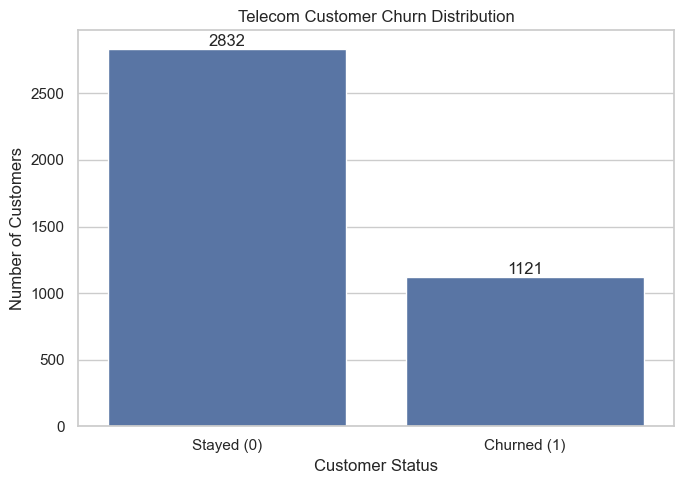

In [220]:
churn_counts = (eda_df["Churn"].value_counts().reindex([0, 1], fill_value=0))
churn_percentages = (churn_counts / churn_counts.sum() * 100)
print("Customer counts:")
print(churn_counts.rename(index={
 0: "Stayed",
 1: "Churned"
}))
print("\nCustomer percentages:")
print(churn_percentages.round(2))
plt.figure(figsize=(7, 5))
ax = sns.countplot(
 data=eda_df,
 x="Churn",
 order=[0, 1]
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
plt.title("Telecom Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
for container in ax.containers:
 ax.bar_label(container)
plt.tight_layout()
plt.show()


#####  

## Customer Age Distribution

##### 

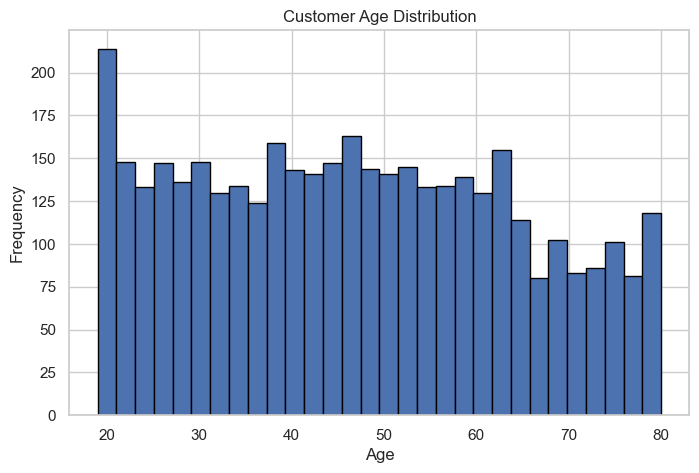

In [221]:
plt.figure(figsize=(8, 5))
plt.hist(eda_df["Age"],bins=30, edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

### Customer Churn Percentage

##### 

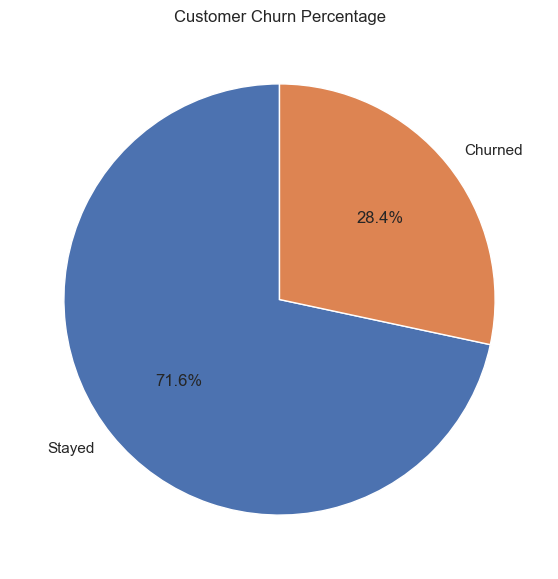

In [222]:
churn_counts = (
 eda_df["Churn"]
    .map({
        0: "Stayed",
        1: "Churned"
    })
    .value_counts()
)

plt.figure(figsize=(7, 7))
plt.pie(
    churn_counts.values,
    labels=churn_counts.index,
    autopct="%.1f%%",
    startangle=90
)
plt.title("Customer Churn Percentage")
plt.show()

### Churn Rate by Tenure

##### 

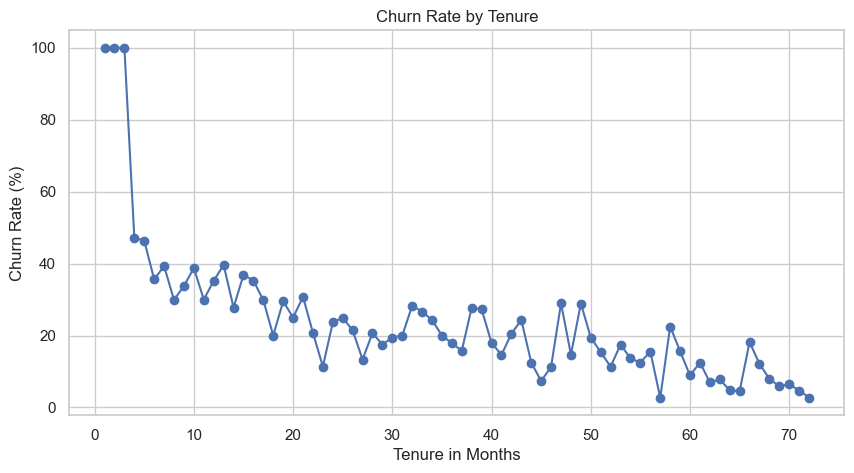

In [223]:
tenure_churn = (eda_df.groupby("Tenure in Months")["Churn"].mean().reset_index())
tenure_churn["Churn Rate"] = (tenure_churn["Churn"] * 100)
plt.figure(figsize=(10, 5))
plt.plot(
    tenure_churn["Tenure in Months"],
    tenure_churn["Churn Rate"],
    marker="o"
)
plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure in Months")
plt.ylabel("Churn Rate (%)")
plt.show()

### Customer Status by Tenure

##### 

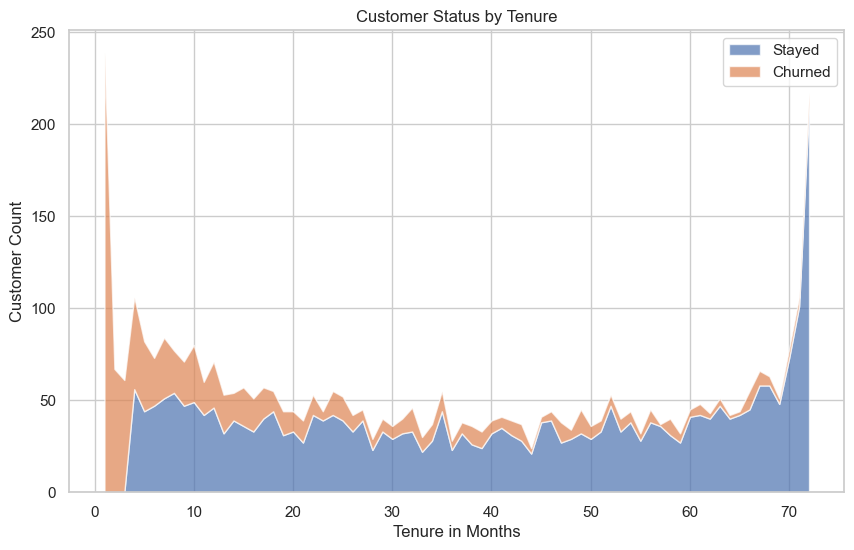

In [224]:
tenure_counts = (eda_df.groupby(["Tenure in Months", "Churn"]).size().unstack(fill_value=0).sort_index())
x = tenure_counts.index
stayed_counts = (
    tenure_counts[0]
    if 0 in tenure_counts.columns
    else np.zeros(len(x))
)
churned_counts = (
    tenure_counts[1]
    if 1 in tenure_counts.columns
    else np.zeros(len(x))
)
plt.figure(figsize=(10, 6))
plt.stackplot(
    x,
    stayed_counts,
    churned_counts,
    labels=[
        "Stayed",
        "Churned"
    ],
    alpha=0.7
)
plt.title("Customer Status by Tenure")
plt.xlabel("Tenure in Months")
plt.ylabel("Customer Count")
plt.legend()
plt.show()

### Monthly Charge Distribution by Churn

##### 

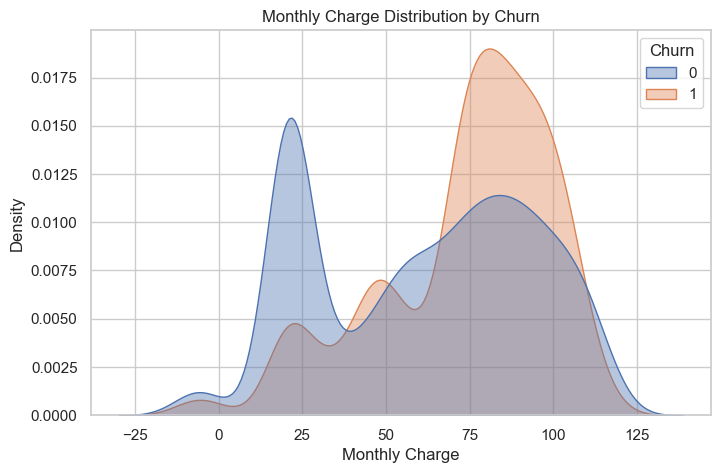

In [225]:
plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=eda_df,
    x="Monthly Charge",
    hue="Churn",
    fill=True,
    common_norm=False,
    alpha=0.4
)
plt.title("Monthly Charge Distribution by Churn")
plt.show()

### ECDF of Tenure by Churn

##### 

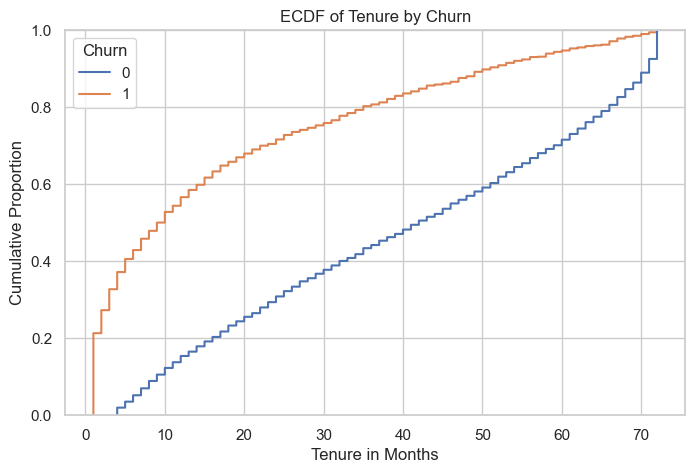

In [226]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(
    data=eda_df,
    x="Tenure in Months",
    hue="Churn"
)
plt.title("ECDF of Tenure by Churn")
plt.xlabel("Tenure in Months")
plt.ylabel("Cumulative Proportion")
plt.show()

### Swarm Plot of Monthly Charges

##### 

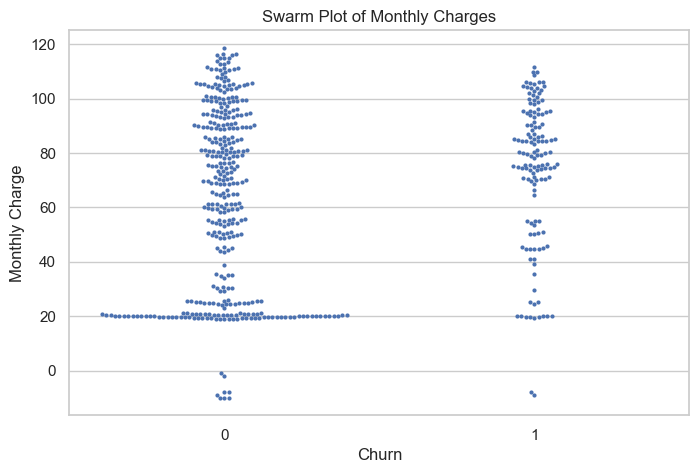

In [227]:
swarm_df = eda_df.sample(min(500, len(eda_df)), random_state=42)
plt.figure(figsize=(8, 5))
sns.swarmplot(
    data=swarm_df,
    x="Churn",
    y="Monthly Charge",
    size=3
)
plt.title("Swarm Plot of Monthly Charges")
plt.show()

### Total Charges Distribution by Churn

##### 

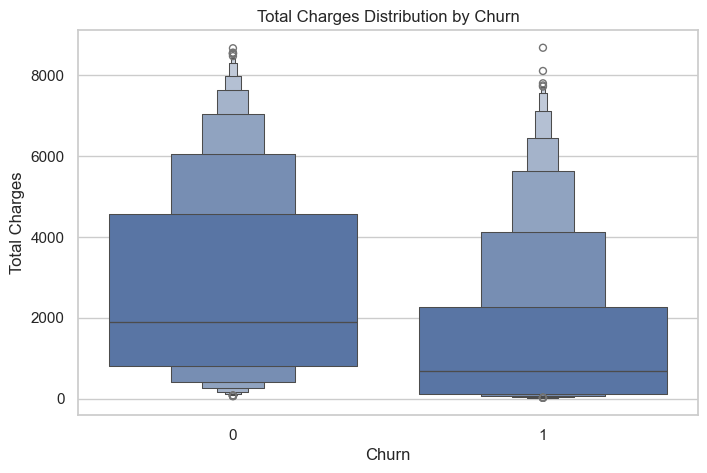

In [228]:
plt.figure(figsize=(8, 5))
sns.boxenplot(data=eda_df, x="Churn", y="Total Charges")
plt.title("Total Charges Distribution by Churn")
plt.show()

### Tenure vs Total Charges by Churn

##### 

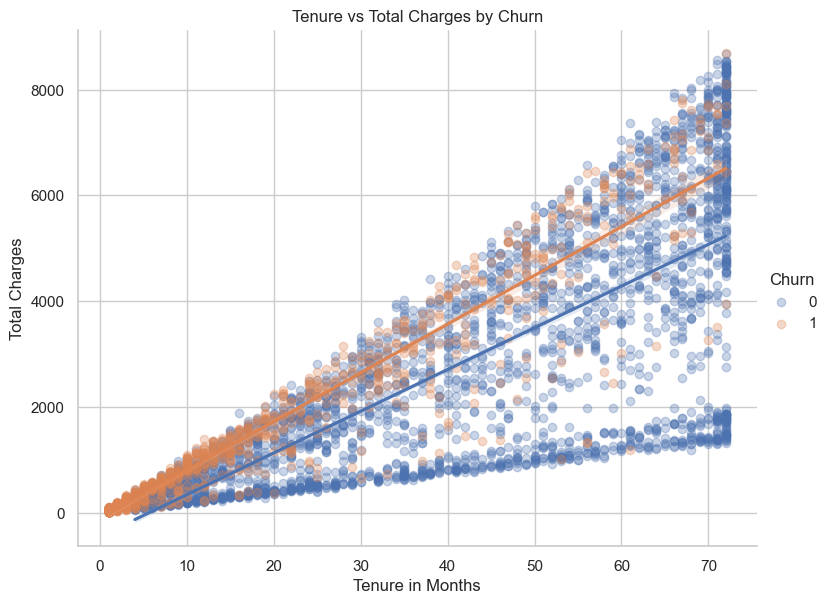

In [229]:
sns.lmplot(
    data=eda_df,
    x="Tenure in Months",
    y="Total Charges",
    hue="Churn",
    height=6,
    aspect=1.3,
    scatter_kws={
        "alpha": 0.3
    }
)
plt.title("Tenure vs Total Charges by Churn")
plt.show()

### Joint Plot

##### 

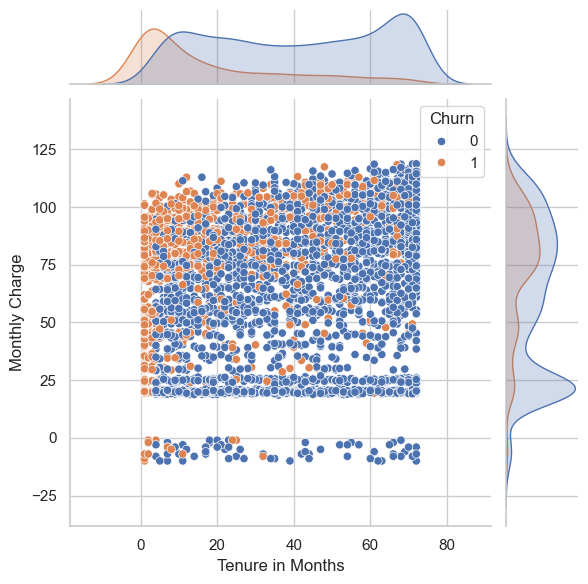

In [230]:
sns.jointplot(
    data=eda_df,
    x="Tenure in Months",
    y="Monthly Charge",
    hue="Churn",
    kind="scatter"
)
plt.show()

### Pair Plot

##### 

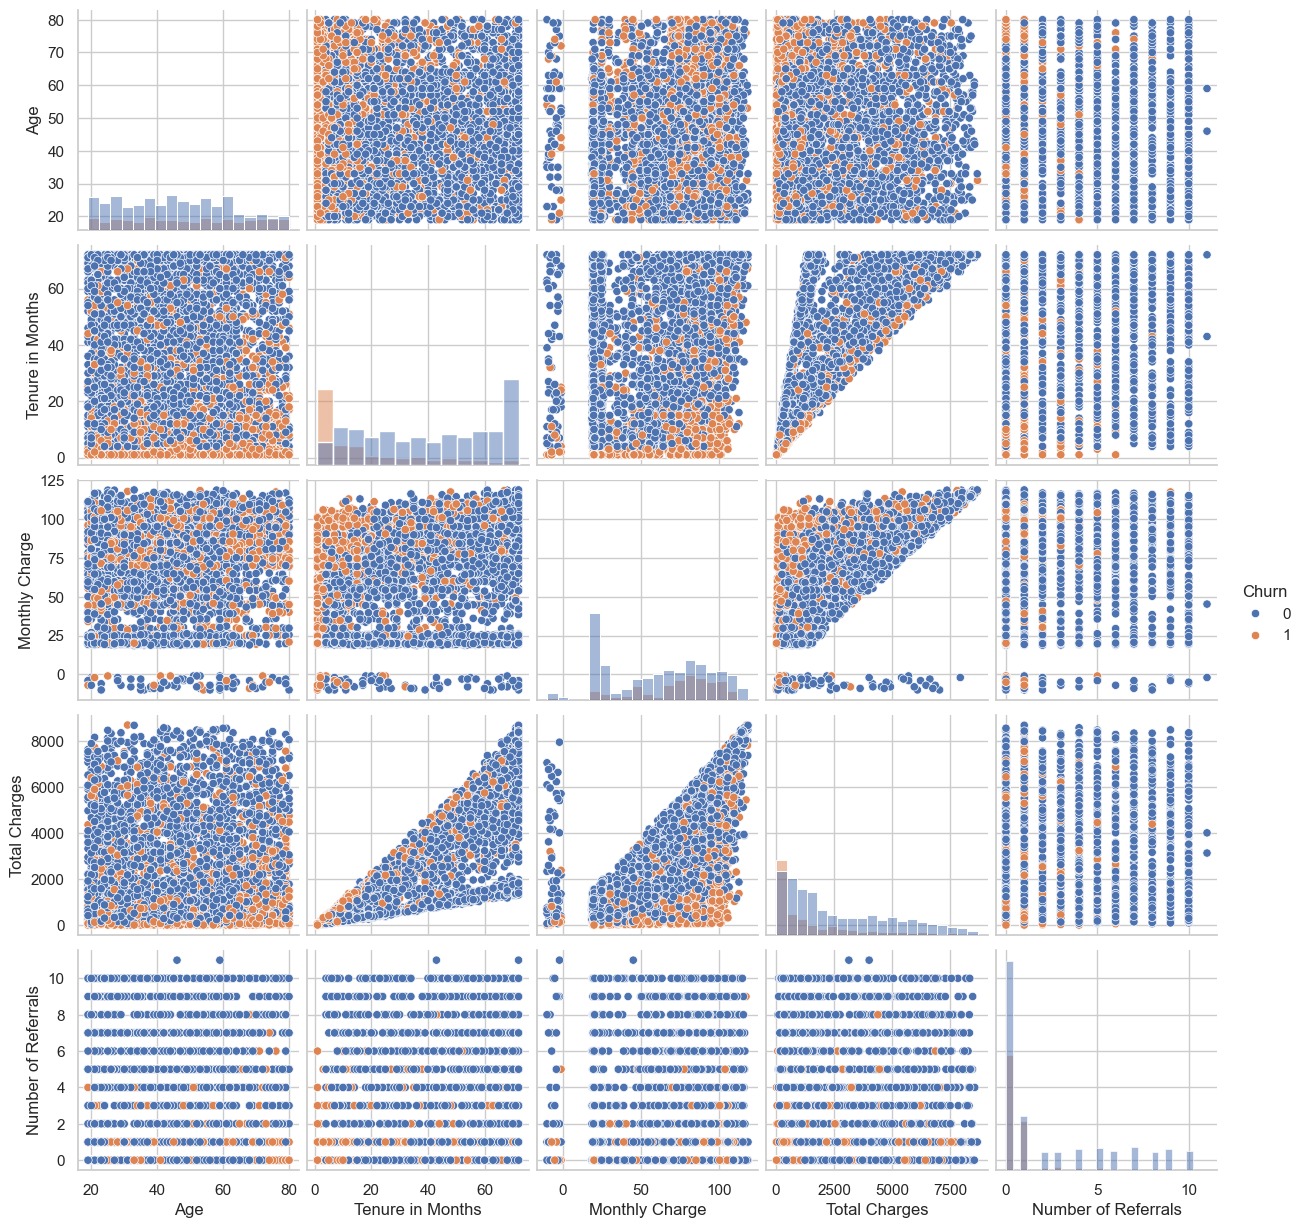

In [231]:
pair_cols = [
    "Age",
    "Tenure in Months",
    "Monthly Charge",
    "Total Charges",
    "Number of Referrals",
    "Churn"
]
sns.pairplot(
    eda_df[pair_cols],
    hue="Churn",
    diag_kind="hist"
)
plt.show()

### Parallel Coordinates

##### 

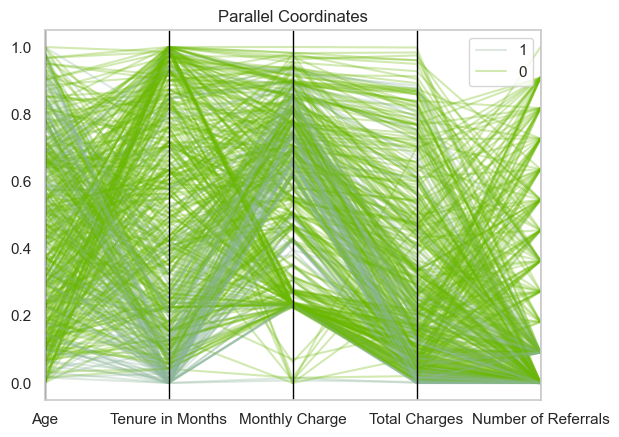

In [232]:
from sklearn.preprocessing import MinMaxScaler

parallel_cols = [
    "Age",
    "Tenure in Months",
    "Monthly Charge",
    "Total Charges",
    "Number of Referrals"
]

parallel_df = eda_df[parallel_cols + ["Churn"]].copy()

scaler = MinMaxScaler()

parallel_df[parallel_cols] = scaler.fit_transform(parallel_df[parallel_cols])
parallel_df["Churn"] = parallel_df["Churn"].astype("category")

parallel_sample = parallel_df.sample(
    min(500, len(parallel_df)),
    random_state=42
)

pd.plotting.parallel_coordinates(parallel_sample, "Churn", alpha=0.3)
plt.title("Parallel Coordinates")
plt.show()

### Correlation Heatmap

##### 

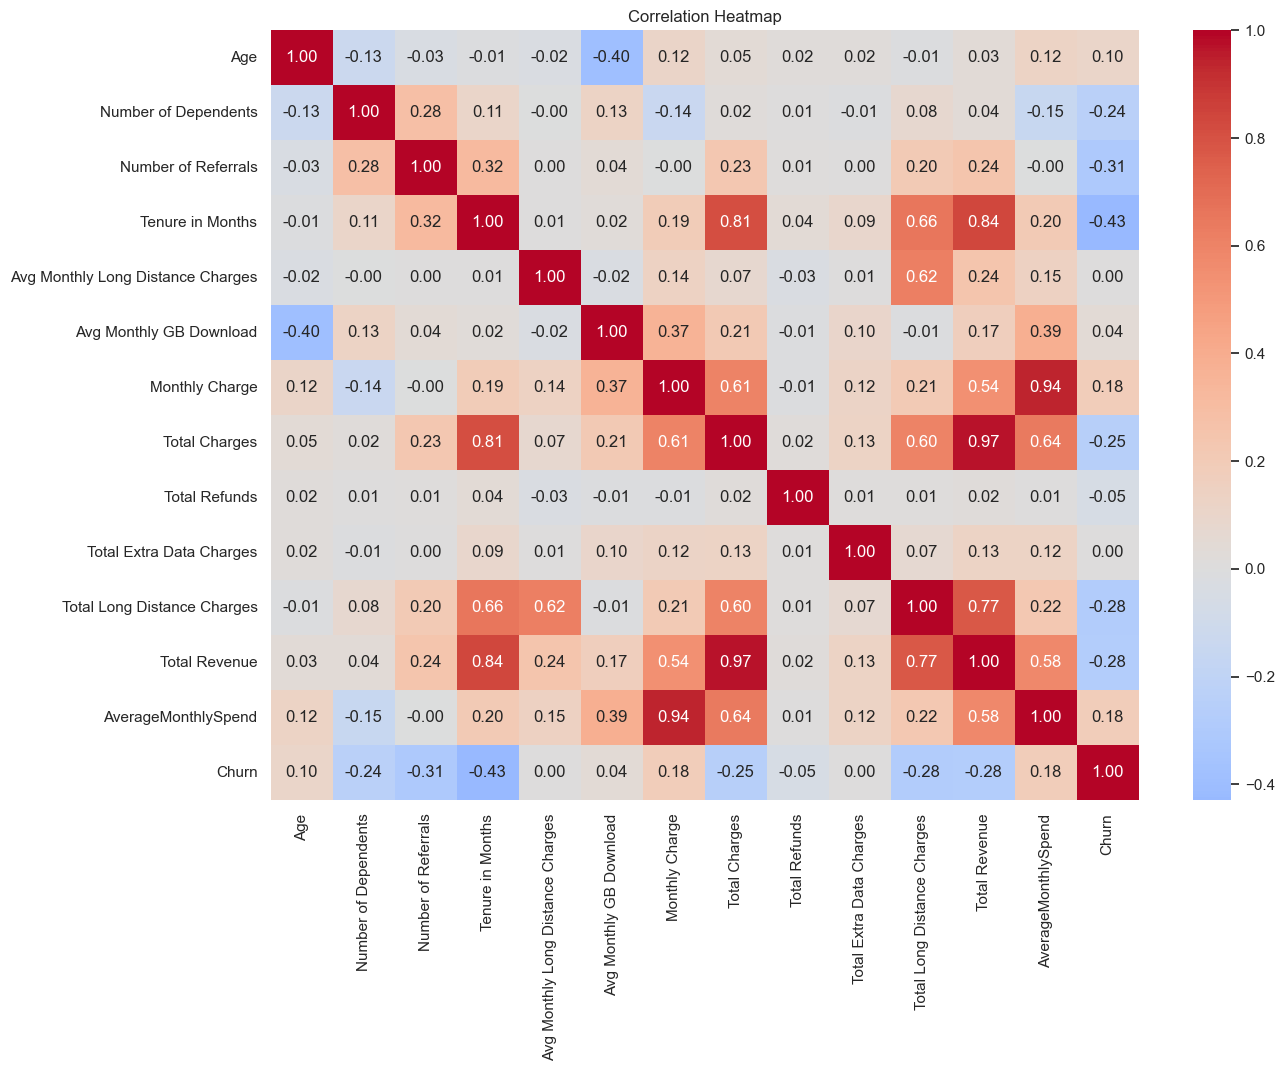

In [233]:
numeric_eda = eda_df.select_dtypes(include=["int64", "float64"])
corr = numeric_eda.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.show()

### Clustered Heatmap

##### 

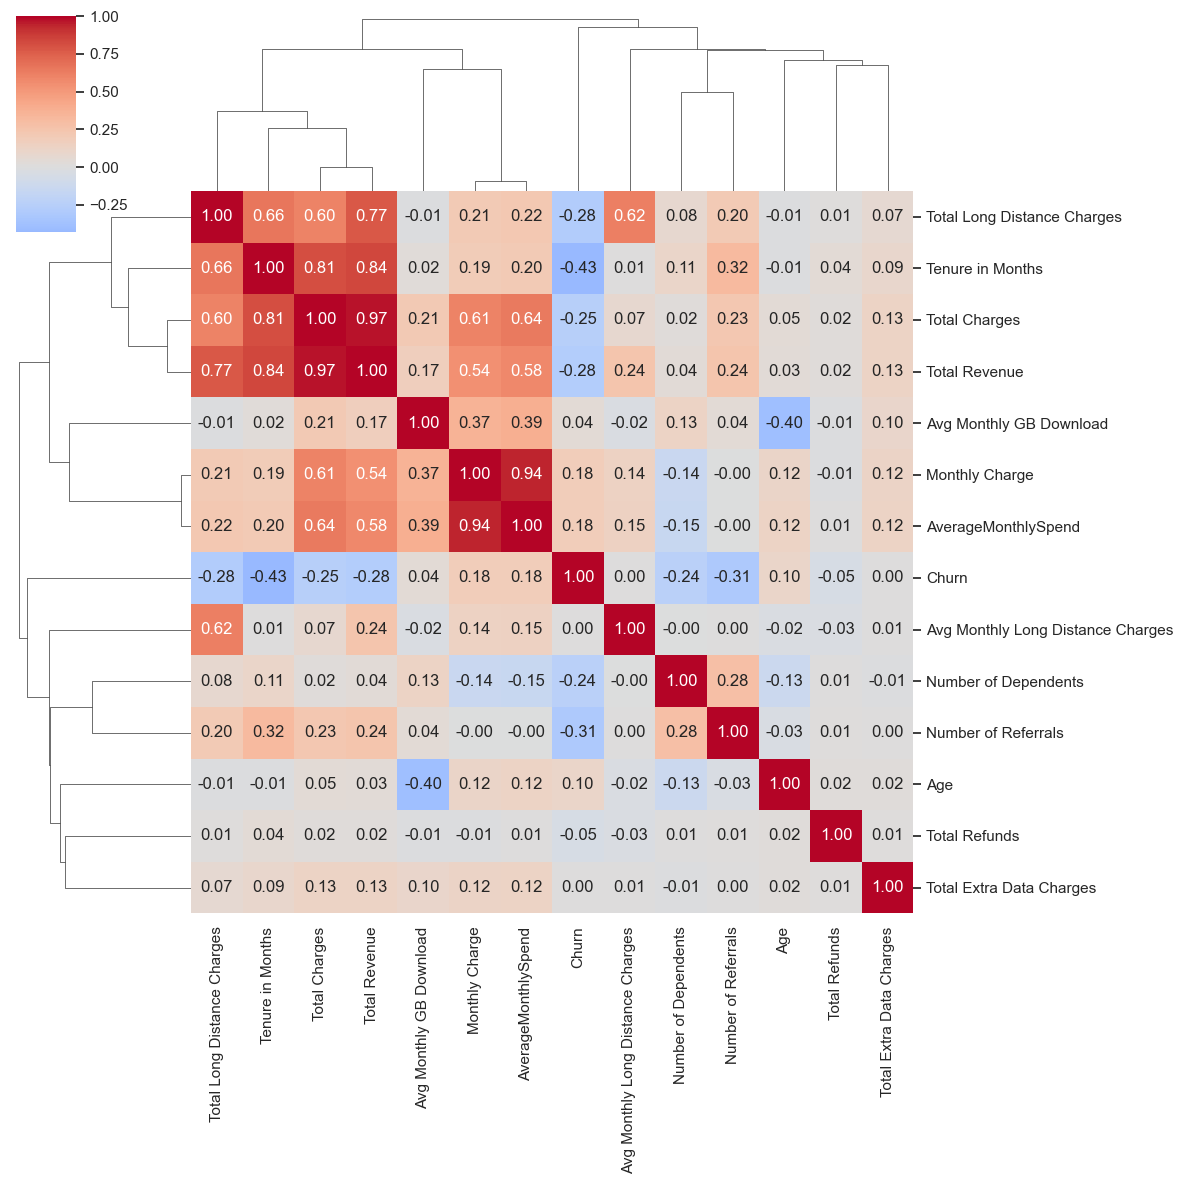

In [234]:
sns.clustermap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    figsize=(12, 12)
)
plt.show()

### Churn Rate by Contract

##### 

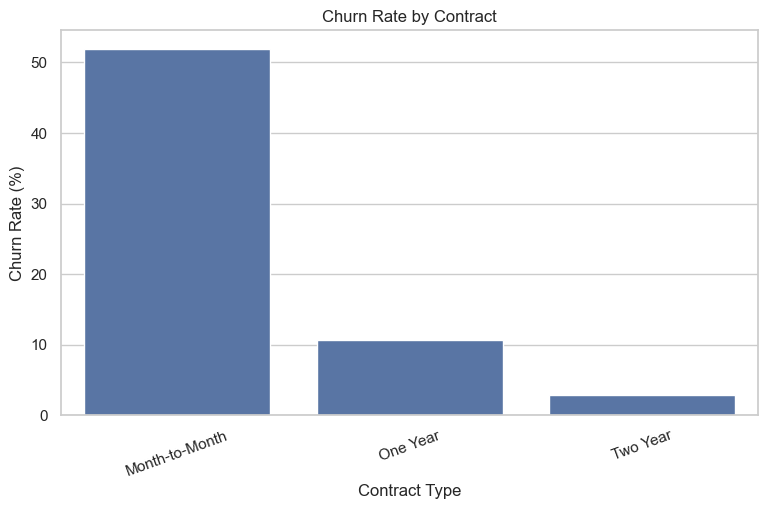

In [235]:
contract_churn = (eda_df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)* 100)
plt.figure(figsize=(9, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values)
plt.title("Churn Rate by Contract")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.show()

### Churn Rate by Monthly Charge

##### 

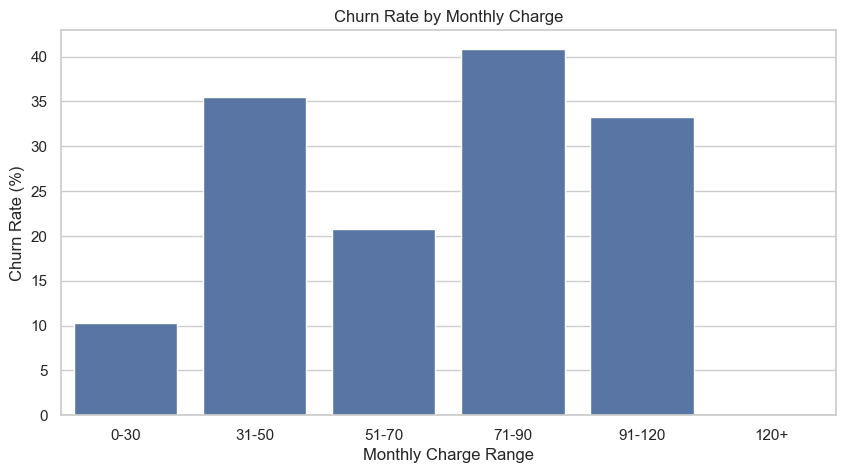

In [236]:
charge_bins = [
    0,
    30,
    50,
    70,
    90,
    120,
    np.inf
]

charge_labels = [
    "0-30",
    "31-50",
    "51-70",
    "71-90",
    "91-120",
    "120+"
]

temp = eda_df.copy()
temp["Charge Bucket"] = pd.cut(temp["Monthly Charge"], bins=charge_bins, labels=charge_labels, include_lowest=True)
charge_churn = (
    temp
    .groupby(
        "Charge Bucket",
        observed=False
    )["Churn"]
    .mean()
    * 100
)
plt.figure(figsize=(10, 5))
sns.barplot(x=charge_churn.index, y=charge_churn.values)
plt.title("Churn Rate by Monthly Charge")
plt.xlabel("Monthly Charge Range")
plt.ylabel("Churn Rate (%)")
plt.show()

### Distribution by Churn

##### 

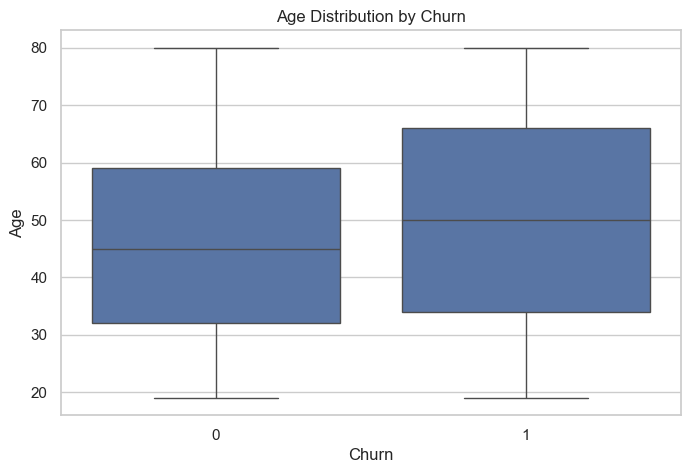

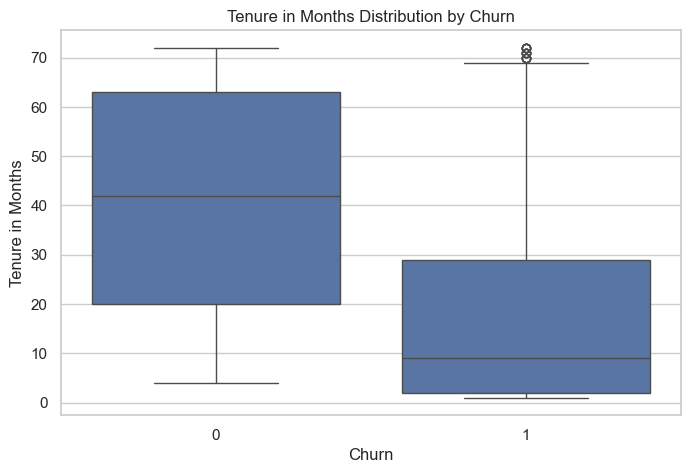

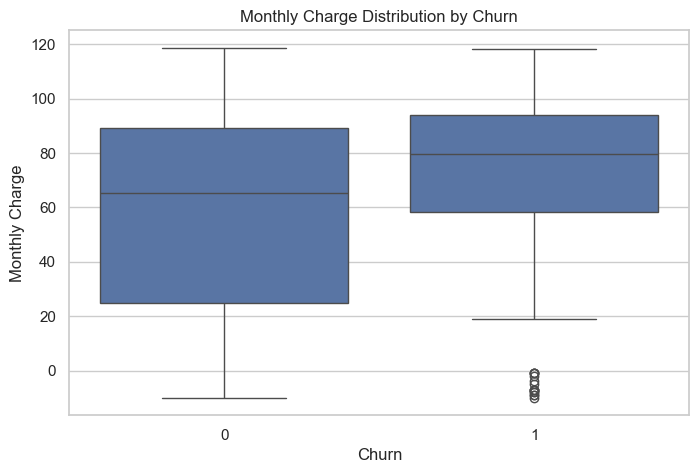

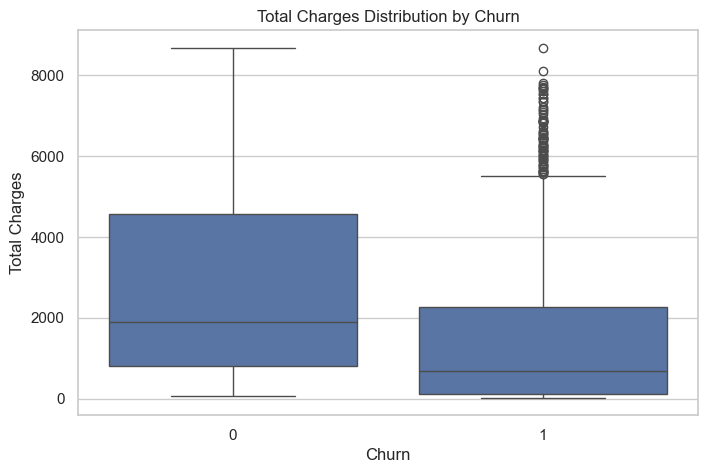

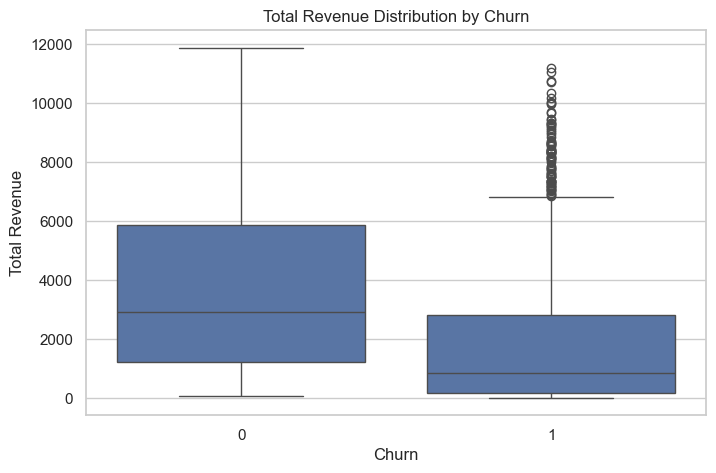

In [237]:
feature_list = [
    "Age",
    "Tenure in Months",
    "Monthly Charge",
    "Total Charges",
    "Total Revenue"
]

for feature in feature_list:

    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=eda_df,
        x="Churn",
        y=feature
    )
    plt.title(f"{feature} Distribution by Churn")
    plt.xlabel("Churn")
    plt.ylabel(feature)
    plt.show()

### Calculate class weights

In [238]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, weights)
)


print(class_weights)

{np.int64(0): np.float64(0.6979166666666666), np.int64(1): np.float64(1.763157894736842)}


## Stage 4: CTGAN, TVAE and WGAN-GP synthetic data generation

### 

#### 

### Step 4.1 — Prepare training-only GAN data

In [239]:
catboost_numeric_medians = (
    X_train[numeric_features]
    .median(numeric_only=True)
    .to_dict()
)

catboost_categorical_fill = {}

for col in categorical_features:

    mode = (
        X_train[col]
        .dropna()
        .astype(str)
        .mode()
    )

    catboost_categorical_fill[col] = (
        str(mode.iloc[0])
        if len(mode)
        else "Unknown"
    )

In [240]:
def prepare_native_catboost(frame):

    out = frame.reindex(
        columns=X_train.columns
    ).copy()

    for col in numeric_features:

        out[col] = (
            pd.to_numeric(
                out[col],
                errors="coerce"
            )
            .fillna(catboost_numeric_medians[col])
        )

    for col in categorical_features:

        out[col] = out[col].map(
            lambda value: str(value).strip()
            if pd.notna(value)
            else catboost_categorical_fill[col]
        )

    return out

In [241]:
X_train_cb = prepare_native_catboost(
    X_train
)

X_val_cb = prepare_native_catboost(
    X_val
)
print(X_train_cb)
print(X_val_cb)


      Gender  Age Married  Number of Dependents  Number of Referrals  \
4339    Male   44      No                     0                    0   
218   Female   41     Yes                     0                    0   
775     Male   66     Yes                     0                    7   
3341  Female   33     Yes                     0                    9   
2240  Female   39     Yes                     0                    1   
...      ...  ...     ...                   ...                  ...   
1396  Female   41     Yes                     0                    4   
6416  Female   63      No                     0                    0   
6415    Male   23     Yes                     1                    0   
3211    Male   63     Yes                     0                    1   
1204  Female   19      No                     0                    0   

      Tenure in Months     Offer Phone Service  \
4339                24  No Offer            No   
218                 55  No Offer   

### Create GAN training dataset

In [242]:
gan_train = prepare_native_catboost(X_train).copy()


In [243]:
gan_train["Churn"] = (y_train.to_numpy(dtype=int))

In [244]:
gan_discrete_columns = (categorical_features + ["Churn"])

In [245]:
print("GAN training shape:", gan_train.shape)
display(gan_train.head())

GAN training shape: (3953, 33)


,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,AverageMonthlySpend,TenureGroup,Churn
4339,Male,44,No,0,0,24,No Offer,No,0.00,No,...,Credit Card,35.75,830.80,0.00,0,0.00,830.80,34.616667,13-24 months,0
218,Female,41,Yes,0,0,55,No Offer,Yes,35.38,Yes,...,Credit Card,66.05,3462.10,44.53,150,1945.90,5513.47,62.947273,49+ months,0
775,Male,66,Yes,0,7,71,Offer A,Yes,30.72,Yes,...,Bank Withdrawal,23.95,1756.20,0.00,0,2181.12,3937.32,24.735211,49+ months,0
3341,Female,33,Yes,0,9,43,No Offer,Yes,49.48,Yes,...,Bank Withdrawal,94.10,4107.30,0.00,0,2127.64,6234.94,95.518605,25-48 months,0
2240,Female,39,Yes,0,1,67,No Offer,Yes,35.03,Yes,...,Bank Withdrawal,111.25,7511.65,0.00,0,2347.01,9858.66,112.114179,49+ months,0


#### 

In [246]:
assert gan_train.isna().sum().sum() == 0

assert "Churn" not in X_train.columns

assert set(
    gan_train["Churn"].unique()
) == {0, 1}

print("GAN training data is ready.")

GAN training data is ready.


###  Train CTGAN


In [247]:
from ctgan import CTGAN

In [248]:
ctgan_model = CTGAN(epochs=50, batch_size=500, verbose=True, enable_gpu=False)

In [249]:
ctgan_model.fit(gan_train, discrete_columns=gan_discrete_columns)

Gen. (-00.51) | Discrim. (+00.11): 100%|██████████| 50/50 [02:05<00:00,  2.52s/it]


In [250]:
synthetic_ctgan = ctgan_model.sample(len(gan_train))

In [251]:
print(synthetic_ctgan.shape)
display(synthetic_ctgan.head())

(3953, 33)


,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,AverageMonthlySpend,TenureGroup,Churn
0,Female,49,No,0,3,-9,Offer D,Yes,33.552761,No,...,Bank Withdrawal,13.380569,5691.911617,25.195470,-1,1.927486,1307.255787,11.292673,49+ months,0
1,Female,66,Yes,0,0,44,No Offer,No,22.738785,Yes,...,Mailed Check,39.376572,-127.476139,18.799158,0,20.123746,-92.529592,10.767994,49+ months,0
2,Female,57,No,0,0,77,No Offer,Yes,50.657784,Yes,...,Credit Card,98.172830,4652.615640,-0.130322,0,1044.844427,707.481027,66.675599,49+ months,0
3,Female,67,No,0,2,-1,Offer A,Yes,15.496508,Yes,...,Credit Card,24.877353,99.383947,0.295761,0,-81.492119,-88.295881,15.560875,7-12 months,0
4,Female,58,Yes,1,0,16,No Offer,Yes,-0.718395,No,...,Credit Card,85.942721,696.393462,36.393104,1,-182.709180,3479.390216,46.657910,49+ months,0


In [252]:
from pathlib import Path
import joblib

GAN_DIR = Path("gan_models")
GAN_DIR.mkdir(exist_ok=True)

synthetic_ctgan.to_csv(
    GAN_DIR / "synthetic_ctgan.csv",
    index=False
)

joblib.dump(
    ctgan_model,
    GAN_DIR / "ctgan_model.pkl"
)

['gan_models\\ctgan_model.pkl']

### Step 4.2 — Train TVAE

#### 

In [253]:
from ctgan import TVAE

#### Create the TVAE model

In [254]:
tvae_model = TVAE(epochs=50, batch_size=500, verbose=True, enable_gpu=False)


### Learn patterns from training data


In [255]:
tvae_model.fit(gan_train, discrete_columns=gan_discrete_columns)

Loss: +27.16: 100%|██████████| 50/50 [00:25<00:00,  1.95it/s]


In [256]:
synthetic_tvae = tvae_model.sample(len(gan_train))

In [257]:
print(synthetic_tvae.shape)
display(synthetic_tvae.head())

(3953, 33)


,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,AverageMonthlySpend,TenureGroup,Churn
0,Male,21,No,0,0,13,No Offer,Yes,1.410952,No,...,Bank Withdrawal,44.855903,777.625186,0.005657,0,30.140483,405.779408,42.608793,13-24 months,0
1,Female,65,No,0,0,13,No Offer,Yes,7.413176,No,...,Bank Withdrawal,81.345161,518.648222,0.034099,0,50.426082,1094.523756,81.339142,25-48 months,0
2,Male,29,No,0,0,11,No Offer,Yes,5.596190,No,...,Bank Withdrawal,74.252421,1006.381574,0.007584,0,-50.594188,534.370487,73.863991,25-48 months,0
3,Male,63,No,0,0,18,No Offer,Yes,12.741701,No,...,Bank Withdrawal,84.530538,792.500557,0.054477,0,302.168356,1800.264648,82.473530,13-24 months,0
4,Female,63,Yes,0,0,57,No Offer,Yes,45.996613,Yes,...,Bank Withdrawal,106.079812,6110.425523,0.026029,0,531.678321,8764.547340,105.873886,49+ months,0


In [258]:
synthetic_tvae.to_csv(
    GAN_DIR / "synthetic_tvae.csv",
    index=False
)

joblib.dump(
    tvae_model,
    GAN_DIR / "tvae_model.pkl"
)

['gan_models\\tvae_model.pkl']

###  WGAN-GP

#### 

## Step 4.3 — Generate data using WGAN-GP

### 

### * Prepare numerical and categorical data

In [259]:
import tensorflow as tf
from tensorflow import keras # type: ignore

tf.random.set_seed(42)

wgan_source = gan_train.copy()

wgan_categories = gan_discrete_columns

wgan_numeric = [
    col for col in wgan_source.columns
    if col not in wgan_categories
]

### * Apply scaling and encoding

In [260]:
wgan_scaler = MinMaxScaler(
    feature_range=(-1, 1)
)

numeric_array = wgan_scaler.fit_transform(
    wgan_source[wgan_numeric]
)

wgan_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

categorical_array = wgan_encoder.fit_transform(
    wgan_source[wgan_categories].astype(str)
)

categorical_array = categorical_array * 2 - 1

wgan_real = np.concatenate(
    [numeric_array, categorical_array],
    axis=1
).astype("float32")

print("WGAN Training Shape:", wgan_real.shape)

WGAN Training Shape: (3953, 64)


### * Build the Generator

In [261]:
noise_dim = 32
data_dim = wgan_real.shape[1]

generator = keras.Sequential([
    keras.layers.Input(shape=(noise_dim,)),

    keras.layers.Dense(128),
    keras.layers.LeakyReLU(
        negative_slope=0.2
    ),

    keras.layers.Dense(128),
    keras.layers.LeakyReLU(
        negative_slope=0.2
    ),

    keras.layers.Dense(
        data_dim,
        activation="tanh"
    )
])

### * Build the Critic

In [262]:
critic = keras.Sequential([
    keras.layers.Input(shape=(data_dim,)),

    keras.layers.Dense(128),
    keras.layers.LeakyReLU(
        negative_slope=0.2
    ),

    keras.layers.Dense(128),
    keras.layers.LeakyReLU(
        negative_slope=0.2
    ),

    keras.layers.Dense(1)
])

### *Create optimizers

In [263]:
g_optimizer = keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.0,
    beta_2=0.9
)

d_optimizer = keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.0,
    beta_2=0.9
)

LAMBDA_GP = 10.0
CRITIC_STEPS = 3

### *Create the training step

In [264]:
@tf.function
def wgan_step(real_batch):

    batch_size = tf.shape(real_batch)[0]

    # Train Critic
    for _ in range(CRITIC_STEPS):

        with tf.GradientTape() as disc_tape:

            noise = tf.random.normal(
                (batch_size, noise_dim)
            )

            fake_batch = tf.stop_gradient(
                generator(noise, training=True)
            )

            real_score = critic(
                real_batch,
                training=True
            )

            fake_score = critic(
                fake_batch,
                training=True
            )

            # Interpolate real and fake
            alpha = tf.random.uniform(
                (batch_size, 1)
            )

            interpolated = (
                real_batch
                + alpha * (fake_batch - real_batch)
            )

            # Gradient penalty
            with tf.GradientTape() as gp_tape:
                gp_tape.watch(interpolated)

                interpolated_score = critic(
                    interpolated,
                    training=True
                )

            gradients = gp_tape.gradient(
                interpolated_score,
                interpolated
            )

            gradient_norm = tf.sqrt(
                tf.reduce_sum(
                    tf.square(gradients),
                    axis=1
                ) + 1e-12
            )

            gp = tf.reduce_mean(
                tf.square(gradient_norm - 1.0)
            )

            critic_loss = (
                tf.reduce_mean(fake_score)
                - tf.reduce_mean(real_score)
                + LAMBDA_GP * gp
            )

        critic_gradients = disc_tape.gradient(
            critic_loss,
            critic.trainable_variables
        )

        d_optimizer.apply_gradients(
            zip(
                critic_gradients,
                critic.trainable_variables
            )
        )

    # Train Generator
    with tf.GradientTape() as gen_tape:

        noise = tf.random.normal(
            (batch_size, noise_dim)
        )

        generated = generator(
            noise,
            training=True
        )

        generator_loss = -tf.reduce_mean(
            critic(generated, training=True)
        )

    generator_gradients = gen_tape.gradient(
        generator_loss,
        generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(
            generator_gradients,
            generator.trainable_variables
        )
    )

    return critic_loss, generator_loss

### *Train WGAN-GP

In [265]:
dataset = (
    tf.data.Dataset
    .from_tensor_slices(wgan_real)
    .shuffle(len(wgan_real), seed=42)
    .batch(64)
)

WGAN_EPOCHS = 10

for epoch in range(WGAN_EPOCHS):

    for batch in dataset:
        critic_loss, generator_loss = wgan_step(
            batch
        )

    print(
        f"Epoch {epoch + 1}/{WGAN_EPOCHS}",
        f"Critic Loss: {float(critic_loss):.4f}",
        f"Generator Loss: {float(generator_loss):.4f}"
    )

Epoch 1/10 Critic Loss: -3.8821 Generator Loss: -1.2280
Epoch 2/10 Critic Loss: -4.0800 Generator Loss: -2.2144
Epoch 3/10 Critic Loss: -3.9521 Generator Loss: -2.0985
Epoch 4/10 Critic Loss: -4.0577 Generator Loss: -2.1211
Epoch 5/10 Critic Loss: -3.8070 Generator Loss: -2.1779
Epoch 6/10 Critic Loss: -3.3757 Generator Loss: -2.4936
Epoch 7/10 Critic Loss: -3.2629 Generator Loss: -2.5390
Epoch 8/10 Critic Loss: -3.0189 Generator Loss: -2.8336
Epoch 9/10 Critic Loss: -2.5727 Generator Loss: -2.8619
Epoch 10/10 Critic Loss: -2.5628 Generator Loss: -2.9837


### *Generate synthetic data

In [266]:
generated_array = generator(
    tf.random.normal(
        (len(gan_train), noise_dim)
    ),
    training=False
).numpy()

n_numeric = len(wgan_numeric)

decoded_numeric = (
    wgan_scaler.inverse_transform(
        generated_array[:, :n_numeric]
    )
)

synthetic_wgan = pd.DataFrame(
    decoded_numeric,
    columns=wgan_numeric
)

In [267]:
offset = n_numeric

for i, col in enumerate(wgan_categories):

    categories = wgan_encoder.categories_[i]

    width = len(categories)

    block = generated_array[
        :,
        offset:offset + width
    ]

    synthetic_wgan[col] = categories[
        np.argmax(block, axis=1)
    ]

    offset += width

synthetic_wgan["Churn"] = pd.to_numeric(
    synthetic_wgan["Churn"],
    errors="coerce"
)

print(synthetic_wgan.shape)

display(synthetic_wgan.head())

(3953, 33)


,Age,Number of Dependents,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,...,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,TenureGroup,Churn
0,30.415476,0.130811,2.663805,8.049335,21.283606,18.390068,29.771681,221.820724,0.166684,0.629193,...,No,No,No,No,No,Month-to-Month,No,Credit Card,49+ months,0
1,36.077122,0.521000,7.468782,59.730465,6.751343,39.668552,85.578369,2913.559570,0.516082,59.362125,...,No,No,Yes,Yes,No,Two Year,Yes,Bank Withdrawal,49+ months,0
2,70.886467,0.209644,0.021537,38.282986,41.885704,45.744530,110.492439,1946.643066,1.705674,2.697431,...,Yes,Yes,Yes,No,Yes,One Year,Yes,Credit Card,49+ months,0
3,40.490108,0.228002,1.406675,67.824295,22.788111,46.611916,93.582077,5823.685059,0.452316,2.186559,...,Yes,Yes,Yes,Yes,Yes,Two Year,No,Credit Card,49+ months,0
4,27.167006,0.826648,6.820145,40.470943,14.271465,10.768523,17.494213,3495.905762,0.752738,17.166916,...,Yes,No,Yes,No,No,Month-to-Month,Yes,Credit Card,49+ months,0


### *Save WGAN-GP

In [268]:
synthetic_wgan.to_csv(
    GAN_DIR / "synthetic_wgan.csv",
    index=False
)

generator.save(
    GAN_DIR / "wgan_generator.keras"
)

joblib.dump(
    wgan_scaler,
    GAN_DIR / "wgan_numeric_scaler.pkl"
)

joblib.dump(
    wgan_encoder,
    GAN_DIR / "wgan_categorical_encoder.pkl"
)

joblib.dump(
    {
        "numeric_cols": wgan_numeric,
        "categorical_cols": wgan_categories,
        "noise_dim": noise_dim
    },
    GAN_DIR / "wgan_metadata.pkl"
)

['gan_models\\wgan_metadata.pkl']

### Compare real and synthetic customer data

In [269]:
display(synthetic_ctgan)

,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,AverageMonthlySpend,TenureGroup,Churn
0,Female,49,No,0,3,-9,Offer D,Yes,33.552761,No,...,Bank Withdrawal,13.380569,5691.911617,25.195470,-1,1.927486,1307.255787,11.292673,49+ months,0
1,Female,66,Yes,0,0,44,No Offer,No,22.738785,Yes,...,Mailed Check,39.376572,-127.476139,18.799158,0,20.123746,-92.529592,10.767994,49+ months,0
2,Female,57,No,0,0,77,No Offer,Yes,50.657784,Yes,...,Credit Card,98.172830,4652.615640,-0.130322,0,1044.844427,707.481027,66.675599,49+ months,0
3,Female,67,No,0,2,-1,Offer A,Yes,15.496508,Yes,...,Credit Card,24.877353,99.383947,0.295761,0,-81.492119,-88.295881,15.560875,7-12 months,0
4,Female,58,Yes,1,0,16,No Offer,Yes,-0.718395,No,...,Credit Card,85.942721,696.393462,36.393104,1,-182.709180,3479.390216,46.657910,49+ months,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3948,Male,24,No,0,4,10,No Offer,Yes,42.356891,Yes,...,Credit Card,83.874181,1186.193220,0.073061,1,-93.607575,802.781297,39.040373,0-6 months,0
3949,Male,61,Yes,0,6,16,Offer D,Yes,3.557364,Yes,...,Credit Card,14.303883,298.876287,0.118933,1,-198.497935,-784.510863,77.531805,13-24 months,1
3950,Male,35,No,0,0,47,Offer A,Yes,2.094675,No,...,Bank Withdrawal,55.229560,5017.416502,38.710483,0,30.207099,5743.328212,52.027278,25-48 months,1
3951,Male,49,Yes,0,0,60,No Offer,No,31.864721,Yes,...,Bank Withdrawal,94.879837,3438.159653,0.314659,1,-82.317455,1448.583626,80.979118,25-48 months,0


In [270]:
display(synthetic_tvae)


,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,AverageMonthlySpend,TenureGroup,Churn
0,Male,21,No,0,0,13,No Offer,Yes,1.410952,No,...,Bank Withdrawal,44.855903,777.625186,0.005657,0,30.140483,405.779408,42.608793,13-24 months,0
1,Female,65,No,0,0,13,No Offer,Yes,7.413176,No,...,Bank Withdrawal,81.345161,518.648222,0.034099,0,50.426082,1094.523756,81.339142,25-48 months,0
2,Male,29,No,0,0,11,No Offer,Yes,5.596190,No,...,Bank Withdrawal,74.252421,1006.381574,0.007584,0,-50.594188,534.370487,73.863991,25-48 months,0
3,Male,63,No,0,0,18,No Offer,Yes,12.741701,No,...,Bank Withdrawal,84.530538,792.500557,0.054477,0,302.168356,1800.264648,82.473530,13-24 months,0
4,Female,63,Yes,0,0,57,No Offer,Yes,45.996613,Yes,...,Bank Withdrawal,106.079812,6110.425523,0.026029,0,531.678321,8764.547340,105.873886,49+ months,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3948,Male,19,Yes,0,0,60,No Offer,Yes,10.423768,No,...,Bank Withdrawal,63.044815,3094.058696,0.074149,0,104.023315,3067.980712,82.806095,49+ months,0
3949,Male,56,Yes,0,0,13,No Offer,Yes,6.317992,No,...,Bank Withdrawal,22.363752,1372.756472,0.027285,0,662.155456,738.255455,25.311957,25-48 months,0
3950,Male,17,Yes,0,0,59,No Offer,Yes,48.198561,No,...,Bank Withdrawal,72.537544,3617.176392,-0.047463,0,1269.690612,5900.806510,87.386068,49+ months,0
3951,Male,19,No,0,0,29,No Offer,Yes,2.994740,No,...,Credit Card,49.740382,644.667668,-0.040223,0,50.672304,1726.106488,38.501721,13-24 months,0


In [271]:
display(synthetic_wgan)

,Age,Number of Dependents,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,...,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,TenureGroup,Churn
0,30.415476,0.130811,2.663805,8.049335,21.283606,18.390068,29.771681,221.820724,0.166684,0.629193,...,No,No,No,No,No,Month-to-Month,No,Credit Card,49+ months,0
1,36.077122,0.521000,7.468782,59.730465,6.751343,39.668552,85.578369,2913.559570,0.516082,59.362125,...,No,No,Yes,Yes,No,Two Year,Yes,Bank Withdrawal,49+ months,0
2,70.886467,0.209644,0.021537,38.282986,41.885704,45.744530,110.492439,1946.643066,1.705674,2.697431,...,Yes,Yes,Yes,No,Yes,One Year,Yes,Credit Card,49+ months,0
3,40.490108,0.228002,1.406675,67.824295,22.788111,46.611916,93.582077,5823.685059,0.452316,2.186559,...,Yes,Yes,Yes,Yes,Yes,Two Year,No,Credit Card,49+ months,0
4,27.167006,0.826648,6.820145,40.470943,14.271465,10.768523,17.494213,3495.905762,0.752738,17.166916,...,Yes,No,Yes,No,No,Month-to-Month,Yes,Credit Card,49+ months,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3948,76.511238,0.349738,0.720666,5.538193,46.673149,44.454124,79.870880,1190.573364,1.666920,2.529082,...,No,No,No,No,Yes,One Year,Yes,Bank Withdrawal,13-24 months,0
3949,73.358315,0.500908,0.043752,22.465868,22.770720,37.787918,103.779556,1257.815430,2.742298,3.738065,...,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,0-6 months,0
3950,45.940308,0.988268,0.119140,56.118038,29.958042,17.632822,108.628273,5797.169434,1.235433,1.827009,...,Yes,Yes,Yes,Yes,Yes,One Year,Yes,Credit Card,49+ months,0
3951,32.860149,0.350488,6.358508,27.557751,5.149722,44.250656,59.467194,913.475159,5.345843,29.566713,...,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,7-12 months,1


### Check missing values and churn distribution

In [272]:
synthetic_datasets = {
    "CTGAN": synthetic_ctgan,
    "TVAE": synthetic_tvae,
    "WGAN-GP": synthetic_wgan
}

for name, data in synthetic_datasets.items():

    print("\nModel:", name)

    print("Shape:", data.shape)

    print(
        "Missing Values:",
        data.isnull().sum().sum()
    )

    print(
        "Churn Distribution:",
        data["Churn"].value_counts(
            normalize=True
        )
    )


Model: CTGAN
Shape: (3953, 33)
Missing Values: 0
Churn Distribution: Churn
0    0.754364
1    0.245636
Name: proportion, dtype: float64

Model: TVAE
Shape: (3953, 33)
Missing Values: 0
Churn Distribution: Churn
0    0.89274
1    0.10726
Name: proportion, dtype: float64

Model: WGAN-GP
Shape: (3953, 33)
Missing Values: 0
Churn Distribution: Churn
0    0.718695
1    0.281305
Name: proportion, dtype: float64


### Compare monthly charge distributions

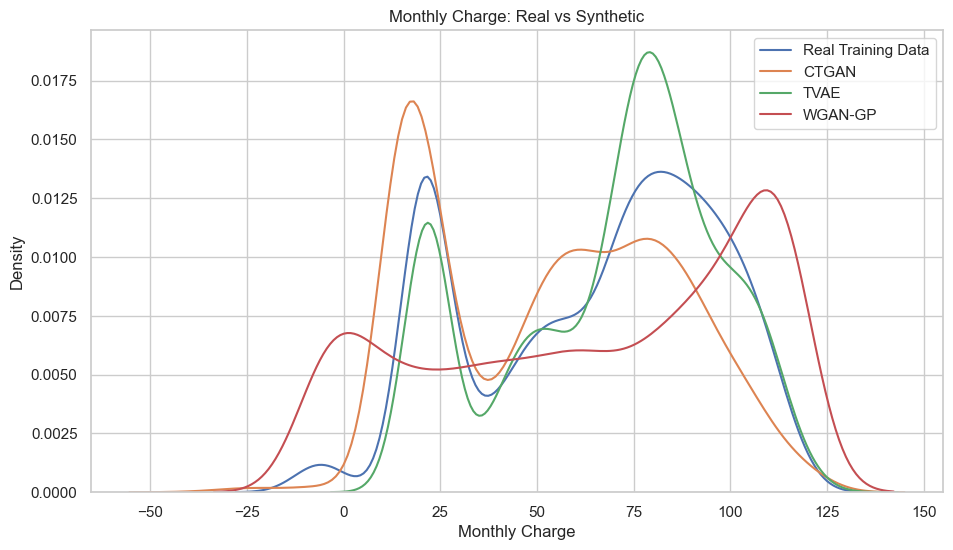

In [273]:
plt.figure(figsize=(11, 6))

sns.kdeplot(
    data=gan_train,
    x="Monthly Charge",
    label="Real Training Data"
)

for name, data in synthetic_datasets.items():

    sns.kdeplot(
        data=data,
        x="Monthly Charge",
        label=name
    )

plt.title(
    "Monthly Charge: Real vs Synthetic"
)

plt.legend()
plt.show()

### Correct important engineered features

In [274]:
def repair_engineered_features(data):

    data = data.copy()

    data["AverageMonthlySpend"] = (
        data["Total Charges"]
        /
        data["Tenure in Months"].replace(
            0, np.nan
        )
    )

    data["TenureGroup"] = pd.cut(
        data["Tenure in Months"],
        bins=[-np.inf, 6, 12, 24, 48, np.inf],
        labels=[
            "0-6 months",
            "7-12 months",
            "13-24 months",
            "25-48 months",
            "49+ months"
        ]
    ).astype(str)

    return data

### Add synthetic data to real training data

In [275]:
selected_synthetic = synthetic_datasets["CTGAN"]

n_synthetic = min(
    len(selected_synthetic),
    len(X_train) // 2
)

selected_synthetic = selected_synthetic.sample(
    n=n_synthetic,
    random_state=42
)

X_synth = selected_synthetic.drop(
    columns="Churn"
).reindex(columns=X_train.columns)

y_synth = (
    selected_synthetic["Churn"]
    .astype(int)
)

X_train_augmented = pd.concat(
    [
        X_train.reset_index(drop=True),
        X_synth.reset_index(drop=True)
    ],
    ignore_index=True
)

y_train_augmented = pd.concat(
    [
        y_train.reset_index(drop=True),
        y_synth.reset_index(drop=True)
    ],
    ignore_index=True
)

print(
    "Augmented Training Size:",
    X_train_augmented.shape
)

Augmented Training Size: (5929, 32)


### Train CatBoost with synthetic data

In [276]:
from catboost import CatBoostClassifier

X_train_aug_cb = prepare_native_catboost(
    X_train_augmented
)

catboost_gan = CatBoostClassifier(
    iterations=500,
    depth=5,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False
)

catboost_gan.fit(
    X_train_aug_cb,
    y_train_augmented,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=40
)

CatBoostClassifier(depth=5, eval_metric='AUC', iterations=500, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=False)

In [277]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

val_proba = catboost_gan.predict_proba(
    X_val_cb
)[:, 1]

val_pred = (
    val_proba >= 0.5
).astype(int)

print(
    "Validation Accuracy:",
    accuracy_score(y_val, val_pred)
)

print(
    "Validation F1:",
    f1_score(y_val, val_pred)
)

print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val, val_proba)
)

Validation Accuracy: 0.8732928679817906
Validation F1: 0.750373692077728
Validation ROC-AUC: 0.9293001676787819


## Stage 5 — Machine Learning Models Training
#### Continue your existing project using the X_train, y_train, X_val, y_val, and make_preprocessor() variables from your previous Pipeline steps.

In [278]:
X_train_fit = X_train.copy()
y_train_fit = y_train.copy()

X_train_fit_ready = np.asarray(
    preprocessor.transform(X_train_fit),
    dtype=np.float32
)

X_train_fit_cb = prepare_native_catboost(
    X_train_fit
)

X_val_ready = np.asarray(
    preprocessor.transform(X_val),
    dtype=np.float32
)

X_val_cb = prepare_native_catboost(X_val)

### Step 5.2: Logistic Regression Training
#### 

In [279]:
from sklearn.linear_model import LogisticRegression

In [280]:
lr_model = LogisticRegression(max_iter=2500, C=1.0, random_state=42)


In [281]:
lr_model.fit(X_train_fit_ready, y_train_fit)


LogisticRegression(max_iter=2500, random_state=42)

In [282]:
lr_probabilities = lr_model.predict_proba(X_val_ready)[:, 1]

In [283]:
print(lr_probabilities)

[0.54661182 0.02745266 0.21634611 ... 0.62722327 0.02666529 0.53117222]


#### Explanation: 

### Step 5.3: CatBoost Training

In [284]:
from catboost import CatBoostClassifier

In [285]:
cat_model = CatBoostClassifier(
    iterations=500,
    depth=5,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)


In [286]:
cat_model.fit(
    X_train_fit_cb,
    y_train_fit,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=40
)


CatBoostClassifier(allow_writing_files=False, depth=5, eval_metric='AUC', iterations=500, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=False)

In [287]:
cat_probabilities = cat_model.predict_proba(X_val_cb)[:, 1]

In [288]:
print(cat_probabilities)

[0.49461814 0.05086766 0.16006505 ... 0.96770499 0.02433978 0.19871401]


### step5.4: XGBoost
#### 

In [289]:
from xgboost import XGBClassifier

In [290]:
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42
)


In [291]:
xgb_model.fit(X_train_fit_ready, y_train_fit)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.85, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=400, n_jobs=None,
              num_parallel_tree=None, ...)

In [292]:
xgb_probabilities = xgb_model.predict_proba(X_val_ready)[:, 1]

In [293]:
print(xgb_probabilities)

[0.5574988  0.01079114 0.2400102  ... 0.9949673  0.00398189 0.08120254]


### Explanation:


## Step 5.5: DNN Deep Learning Training


In [294]:
import tensorflow as tf
from tensorflow import keras # type: ignore

dnn_model = keras.Sequential([
    keras.layers.Input(
        shape=(X_train_fit_ready.shape[1],)
    ),

    keras.layers.Dense(
        128, activation="relu"
    ),

    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.35),

    keras.layers.Dense(
        64, activation="relu"
    ),

    keras.layers.Dropout(0.30),

    keras.layers.Dense(
        1, activation="sigmoid"
    )
])

dnn_model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)
dnn_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 128)            │         8,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,897 (66.00 KB)

 Trainable params: 16,641 (65.00 KB)

 Non-trainable params: 256 (1.00 KB)

In [295]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

dnn_history = dnn_model.fit(
    X_train_fit_ready,
    y_train_fit.to_numpy(),

    validation_data=(
        X_val_ready,
        y_val.to_numpy()
    ),

    epochs=70,
    batch_size=32,

    callbacks=[early_stopping]
)

Epoch 1/70
124/124 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7574 - auc: 0.8089 - loss: 0.5151 - val_accuracy: 0.8376 - val_auc: 0.8933 - val_loss: 0.4141
Epoch 2/70
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8237 - auc: 0.8780 - loss: 0.3919 - val_accuracy: 0.8490 - val_auc: 0.9059 - val_loss: 0.3491
Epoch 3/70
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8432 - auc: 0.8966 - loss: 0.3633 - val_accuracy: 0.8558 - val_auc: 0.9094 - val_loss: 0.3372
Epoch 4/70
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8470 - auc: 0.9062 - loss: 0.3451 - val_accuracy: 0.8437 - val_auc: 0.9088 - val_loss: 0.3407
Epoch 5/70
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8492 - auc: 0.9119 - loss: 0.3352 - val_accuracy: 0.8445 - val_auc: 0.9116 - val_loss: 0.3348
Epoch 6/70
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8548 - auc: 0.9150 - loss: 0.3290 - val_accuracy: 0.8543 - val_auc: 0.9111 - val_loss: 0.3353
Epoch 7/70
124/124 ━━━━━━━━━━━━━━━━━━━━

## Step5.6: TabNet Training

#### 

In [296]:
import torch
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_model = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=3,
    gamma=1.3,

    optimizer_fn=torch.optim.Adam,
    optimizer_params={"lr": 0.02},

    seed=42,
    verbose=1
)

tabnet_model.fit(
    X_train=X_train_fit_ready.astype(
        np.float32
    ),

    y_train=y_train_fit.to_numpy(
        dtype=np.int64
    ),

    eval_set=[(
        X_val_ready.astype(np.float32),
        y_val.to_numpy(dtype=np.int64)
    )],

    eval_name=["validation"],
    eval_metric=["auc"],

    max_epochs=80,
    patience=12,
    batch_size=256,
    virtual_batch_size=64
)

c:\Users\SIMON\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.64673 | validation_auc: 0.70928 |  0:00:01s
epoch 1  | loss: 0.49095 | validation_auc: 0.82107 |  0:00:03s
epoch 2  | loss: 0.42994 | validation_auc: 0.85273 |  0:00:06s
epoch 3  | loss: 0.40103 | validation_auc: 0.87688 |  0:00:08s
epoch 4  | loss: 0.39079 | validation_auc: 0.88546 |  0:00:10s
epoch 5  | loss: 0.37614 | validation_auc: 0.89147 |  0:00:12s
epoch 6  | loss: 0.36087 | validation_auc: 0.88554 |  0:00:13s
epoch 7  | loss: 0.35357 | validation_auc: 0.90026 |  0:00:16s
epoch 8  | loss: 0.34159 | validation_auc: 0.89994 |  0:00:18s
epoch 9  | loss: 0.33866 | validation_auc: 0.88915 |  0:00:19s
epoch 10 | loss: 0.34103 | validation_auc: 0.89056 |  0:00:21s
epoch 11 | loss: 0.32878 | validation_auc: 0.89662 |  0:00:22s
epoch 12 | loss: 0.33265 | validation_auc: 0.88916 |  0:00:24s
epoch 13 | loss: 0.31928 | validation_auc: 0.88498 |  0:00:26s
epoch 14 | loss: 0.31815 | validation_auc: 0.87811 |  0:00:27s
epoch 15 | loss: 0.31851 | validation_auc: 0.88367 |  0

c:\Users\SIMON\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [297]:
tabnet_probabilities = (
    tabnet_model.predict_proba(
        X_val_ready.astype(np.float32)
    )[:, 1]
)

In [298]:
print(tabnet_probabilities)

[0.31354526 0.11312709 0.4584866  ... 0.44792333 0.12310473 0.45941702]


#### Explanation: 

## Step 5.7: FT-Transformer Training
### 

In [299]:
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

FT_SEED = 42
np.random.seed(FT_SEED)
torch.manual_seed(FT_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(FT_SEED)
ft_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("FT device:", ft_device)
for name in ("X_train", "X_val", "X_test", "y_train", "y_val", "y_test",
             "preprocessor", "standard_features", "minmax_features"):
    assert name in globals(), f"Missing {name}: preprocessing cells"

FT device: cpu


In [300]:
ft_std_cols = list(standard_features)
ft_mm_cols = list(minmax_features)
ft_num_cols = ft_std_cols + ft_mm_cols
ft_cat_cols = [c for c in X_train.columns if c not in ft_num_cols]

assert set(ft_num_cols).issubset(X_train.columns)
assert len(ft_num_cols) == len(set(ft_num_cols)), "Numeric column duplicate!"
assert set(ft_num_cols).isdisjoint(ft_cat_cols)
assert set(ft_num_cols + ft_cat_cols) == set(X_train.columns)

print("Numerical columns:", len(ft_num_cols), ft_num_cols)
print("Categorical columns:", len(ft_cat_cols), ft_cat_cols)


Numerical columns: 13 ['Number of Dependents', 'Number of Referrals', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Age', 'Tenure in Months', 'Monthly Charge', 'Total Charges', 'Total Revenue', 'AverageMonthlySpend']
Categorical columns: 19 ['Gender', 'Married', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'TenureGroup']


In [301]:
def ft_category_series(df, col):
    return df[col].astype("string").fillna("__MISSING__").str.strip().replace("", "__MISSING__")

ft_vocab = {}
for col in ft_cat_cols:
    unique_values = pd.unique(ft_category_series(X_train, col))
    ft_vocab[col] = {str(value): i + 1 for i, value in enumerate(unique_values)}

ft_cardinalities = [len(ft_vocab[col]) + 1 for col in ft_cat_cols]
print("Embedding sizes:", dict(zip(ft_cat_cols, ft_cardinalities)))


Embedding sizes: {'Gender': 3, 'Married': 3, 'Offer': 7, 'Phone Service': 3, 'Multiple Lines': 3, 'Internet Service': 3, 'Internet Type': 5, 'Online Security': 3, 'Online Backup': 3, 'Device Protection Plan': 3, 'Premium Tech Support': 3, 'Streaming TV': 3, 'Streaming Movies': 3, 'Streaming Music': 3, 'Unlimited Data': 3, 'Contract': 4, 'Paperless Billing': 3, 'Payment Method': 4, 'TenureGroup': 6}


In [302]:
def ft_transform_raw(frame, fitted_preprocessor, std_cols, mm_cols, cat_cols, vocab):
    frame = frame.copy()
    required = std_cols + mm_cols + cat_cols
    missing = [c for c in required if c not in frame.columns]
    if missing:
        raise ValueError(f"Missing FT input columns: {missing}")

    number_parts = []
    if std_cols:
        number_parts.append(np.asarray(
            fitted_preprocessor.named_transformers_["standard"].transform(frame[std_cols]),
            dtype=np.float32))
    if mm_cols:
        number_parts.append(np.asarray(
            fitted_preprocessor.named_transformers_["minmax"].transform(frame[mm_cols]),
            dtype=np.float32))
    x_num = (np.concatenate(number_parts, axis=1) if number_parts
             else np.zeros((len(frame), 0), dtype=np.float32))

    x_cat = np.zeros((len(frame), len(cat_cols)), dtype=np.int64)
    for i, col in enumerate(cat_cols):
        x_cat[:, i] = (ft_category_series(frame, col)
                       .map(vocab[col]).fillna(0).to_numpy(dtype=np.int64))
    if not np.isfinite(x_num).all():
        raise ValueError("Numeric features contain NaN/inf; check fitted imputer and features")
    return x_num, x_cat

ft_transform_kwargs = (preprocessor, ft_std_cols, ft_mm_cols, ft_cat_cols, ft_vocab)
ft_Xtr_num, ft_Xtr_cat = ft_transform_raw(X_train, *ft_transform_kwargs)
ft_Xva_num, ft_Xva_cat = ft_transform_raw(X_val, *ft_transform_kwargs)
ft_ytr = np.asarray(y_train, dtype=np.float32).reshape(-1)
ft_yva = np.asarray(y_val, dtype=np.float32).reshape(-1)

assert ft_Xtr_num.shape[0] == len(ft_ytr)
assert ft_Xtr_cat.shape == (len(ft_ytr), len(ft_cat_cols))
assert all(ft_Xtr_cat[:, i].max() < size for i, size in enumerate(ft_cardinalities))
print("Train numeric:", ft_Xtr_num.shape, "categorical:", ft_Xtr_cat.shape)
print("Val numeric:", ft_Xva_num.shape, "categorical:", ft_Xva_cat.shape)


Train numeric: (3953, 13) categorical: (3953, 19)
Val numeric: (1318, 13) categorical: (1318, 19)


In [303]:
FT_BATCH_SIZE = 128

def ft_loader(x_num, x_cat, y=None, shuffle=False):
    tensors = [torch.from_numpy(x_num), torch.from_numpy(x_cat)]
    if y is not None:
        tensors.append(torch.from_numpy(np.asarray(y, dtype=np.float32)))
    return DataLoader(TensorDataset(*tensors), batch_size=FT_BATCH_SIZE,
                      shuffle=shuffle, num_workers=0)

ft_train_loader = ft_loader(ft_Xtr_num, ft_Xtr_cat, ft_ytr, shuffle=True)
ft_val_loader = ft_loader(ft_Xva_num, ft_Xva_cat, ft_yva, shuffle=False)
print("Training batches:", len(ft_train_loader), "Validation batches:", len(ft_val_loader))


Training batches: 31 Validation batches: 11


In [304]:
class TelecomFTTransformer(nn.Module):
    def __init__(self, n_numeric, cardinalities, d_token=32,
                 n_heads=4, n_layers=2, dropout=0.15):
        super().__init__()
        if d_token % n_heads:
            raise ValueError("d_token must be divisible by n_heads")
        self.num_weight = nn.Parameter(torch.randn(n_numeric, d_token) * 0.02)
        self.num_bias = nn.Parameter(torch.zeros(n_numeric, d_token))
        self.cat_embeddings = nn.ModuleList(
            [nn.Embedding(n_categories, d_token) for n_categories in cardinalities])
        self.cat_bias = nn.Parameter(torch.zeros(len(cardinalities), d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=4*d_token,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))

    def forward(self, x_num, x_cat):
        numeric_tokens = x_num.unsqueeze(-1)*self.num_weight + self.num_bias
        tokens = [numeric_tokens]
        for i, embedding in enumerate(self.cat_embeddings):
            tokens.append(embedding(x_cat[:, i]).unsqueeze(1) + self.cat_bias[i])
        features = torch.cat(tokens, dim=1)
        cls_token = self.cls.expand(features.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls_token, features], dim=1))
        return self.head(encoded[:, 0]).squeeze(-1)  # logit; no sigmoid here

FT_CONFIG = dict(d_token=32, n_heads=4, n_layers=2, dropout=0.15)
ft_model = TelecomFTTransformer(
    n_numeric=len(ft_num_cols), cardinalities=ft_cardinalities, **FT_CONFIG
).to(ft_device)
print(ft_model)


TelecomFTTransformer(
  (cat_embeddings): ModuleList(
    (0-1): 2 x Embedding(3, 32)
    (2): Embedding(7, 32)
    (3-5): 3 x Embedding(3, 32)
    (6): Embedding(5, 32)
    (7-14): 8 x Embedding(3, 32)
    (15): Embedding(4, 32)
    (16): Embedding(3, 32)
    (17): Embedding(4, 32)
    (18): Embedding(6, 32)
  )
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=128, bias=True)
        (dropout): Dropout(p=0.15, inplace=False)
        (linear2): Linear(in_features=128, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.15, inplace=False)
        (dropout2): Dropout(p=

In [305]:
ft_n0 = int((ft_ytr == 0).sum())
ft_n1 = int((ft_ytr == 1).sum())
if ft_n1 == 0 or ft_n0 == 0:
    raise ValueError("Both target classes must be present in training data")
ft_pos_weight = ft_n0 / ft_n1
ft_loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(ft_pos_weight, device=ft_device))
ft_optimizer = torch.optim.AdamW(ft_model.parameters(), lr=8e-4, weight_decay=1e-4)
FT_MAX_EPOCHS, FT_PATIENCE = 35, 7
print("No churn:", ft_n0, "Churn:", ft_n1, "pos_weight:", round(ft_pos_weight, 3))


No churn: 2832 Churn: 1121 pos_weight: 2.526


In [306]:
def ft_predict_proba(model, loader, device):
    model.eval()
    output = []
    with torch.inference_mode():
        for batch in loader:
            x_num, x_cat = batch[:2]
            logits = model(x_num.to(device), x_cat.to(device))
            output.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(output) if output else np.array([], dtype=np.float32)


### FT-Transformer training + early stopping

In [307]:
ft_checkpoint = Path("models/telecom_churn_ft_transformer.pt")
ft_checkpoint.parent.mkdir(parents=True, exist_ok=True)
ft_history = []
ft_best_auc = -np.inf
ft_no_improve = 0
ft_best_epoch = 0

for epoch in range(1, FT_MAX_EPOCHS + 1):
    ft_model.train()
    train_loss_sum = 0.0
    for x_num, x_cat, y_batch in ft_train_loader:
        x_num = x_num.to(ft_device)
        x_cat = x_cat.to(ft_device)
        y_batch = y_batch.to(ft_device)
        ft_optimizer.zero_grad(set_to_none=True)
        logits = ft_model(x_num, x_cat)
        loss = ft_loss_fn(logits, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(ft_model.parameters(), max_norm=1.0)
        ft_optimizer.step()
        train_loss_sum += loss.item() * len(y_batch)
    train_loss = train_loss_sum / len(ft_ytr)

    ft_model.eval()
    val_loss_sum = 0.0
    with torch.inference_mode():
        for x_num, x_cat, y_batch in ft_val_loader:
            logits = ft_model(x_num.to(ft_device), x_cat.to(ft_device))
            val_loss_sum += (ft_loss_fn(logits, y_batch.to(ft_device)).item()
                             * len(y_batch))
    val_loss = val_loss_sum / len(ft_yva)
    val_probs = ft_predict_proba(ft_model, ft_val_loader, ft_device)
    val_auc = roc_auc_score(ft_yva.astype(int), val_probs)
    ft_history.append({"epoch": epoch, "train_loss": train_loss,
                       "val_loss": val_loss, "val_auc": val_auc})
    print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | val_auc={val_auc:.4f}")

    if val_auc > ft_best_auc + 1e-4:
        ft_best_auc, ft_best_epoch, ft_no_improve = val_auc, epoch, 0
        torch.save(ft_model.state_dict(), ft_checkpoint)
    else:
        ft_no_improve += 1
        if ft_no_improve >= FT_PATIENCE:
            print("Early stopping at epoch", epoch)
            break

ft_model.load_state_dict(torch.load(ft_checkpoint, map_location=ft_device, weights_only=True))
ft_model.eval()
print("Best epoch:", ft_best_epoch, "Best val AUC:", round(ft_best_auc, 4))


Epoch 01 | train_loss=0.7144 | val_loss=0.5902 | val_auc=0.9005
Epoch 02 | train_loss=0.5938 | val_loss=0.5659 | val_auc=0.9074
Epoch 03 | train_loss=0.5693 | val_loss=0.6235 | val_auc=0.9121
Epoch 04 | train_loss=0.5393 | val_loss=0.5338 | val_auc=0.9173
Epoch 05 | train_loss=0.5266 | val_loss=0.5670 | val_auc=0.9101
Epoch 06 | train_loss=0.5170 | val_loss=0.5275 | val_auc=0.9188
Epoch 07 | train_loss=0.5069 | val_loss=0.5583 | val_auc=0.9194
Epoch 08 | train_loss=0.5125 | val_loss=0.5115 | val_auc=0.9215
Epoch 09 | train_loss=0.4900 | val_loss=0.5158 | val_auc=0.9202
Epoch 10 | train_loss=0.5022 | val_loss=0.5345 | val_auc=0.9183
Epoch 11 | train_loss=0.4775 | val_loss=0.5010 | val_auc=0.9234
Epoch 12 | train_loss=0.4760 | val_loss=0.5211 | val_auc=0.9262
Epoch 13 | train_loss=0.4816 | val_loss=0.5101 | val_auc=0.9270
Epoch 14 | train_loss=0.4733 | val_loss=0.5224 | val_auc=0.9258
Epoch 15 | train_loss=0.4621 | val_loss=0.5006 | val_auc=0.9293
Epoch 16 | train_loss=0.4758 | val_loss=

### Learning curves

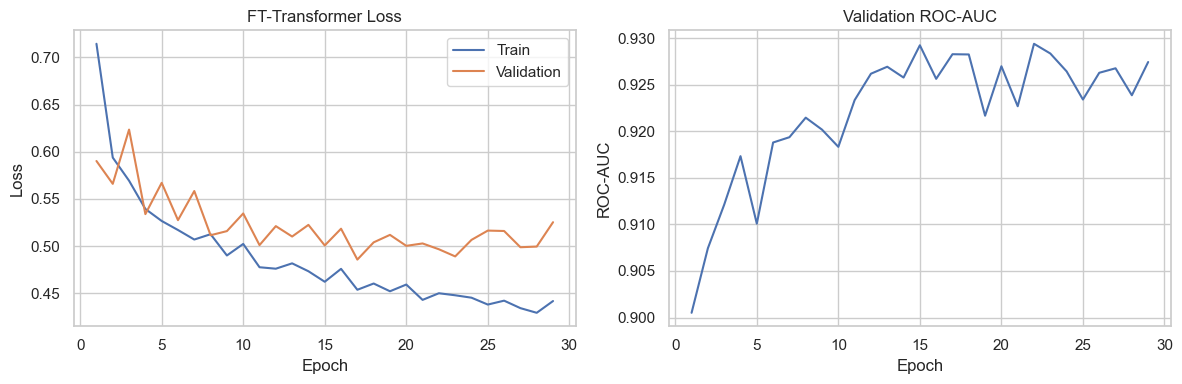

In [308]:
ft_history_df = pd.DataFrame(ft_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ft_history_df["epoch"], ft_history_df["train_loss"], label="Train")
axes[0].plot(ft_history_df["epoch"], ft_history_df["val_loss"], label="Validation")
axes[0].set(title="FT-Transformer Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(ft_history_df["epoch"], ft_history_df["val_auc"])
axes[1].set(title="Validation ROC-AUC", xlabel="Epoch", ylabel="ROC-AUC")
plt.tight_layout()
plt.show()


### Validation metrics + threshold tuning

In [309]:
ft_val_probs = ft_predict_proba(ft_model, ft_val_loader, ft_device)

def ft_evaluate(y_true, probabilities, threshold, split_name):
    truth = np.asarray(y_true, dtype=int).reshape(-1)
    pred = (probabilities >= threshold).astype(int)
    return {"Model": "FT-Transformer", "Split": split_name,
            "Threshold": float(threshold), "Accuracy": accuracy_score(truth, pred),
            "Precision": precision_score(truth, pred, zero_division=0),
            "Recall": recall_score(truth, pred, zero_division=0),
            "F1-score": f1_score(truth, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(truth, probabilities)}

ft_val_default = ft_evaluate(ft_yva, ft_val_probs, 0.5, "Validation")
ft_tuning_rows = [ft_evaluate(ft_yva, ft_val_probs, threshold, "Validation")
                  for threshold in np.arange(0.20, 0.801, 0.01)]
ft_tuning_table = pd.DataFrame(ft_tuning_rows).sort_values(
    ["F1-score", "Recall", "Accuracy"], ascending=False).reset_index(drop=True)
ft_best_threshold = round(float(ft_tuning_table.loc[0, "Threshold"]), 2)
ft_val_tuned = ft_evaluate(ft_yva, ft_val_probs, ft_best_threshold, "Validation")
print("Default threshold:")
display(pd.DataFrame([ft_val_default]).round(4))
print("F1-tuned threshold:", ft_best_threshold)
display(pd.DataFrame([ft_val_tuned]).round(4))

Default threshold:


,Model,Split,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,FT-Transformer,Validation,0.5,0.852,0.7029,0.8289,0.7607,0.9294


F1-tuned threshold: 0.57


,Model,Split,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,FT-Transformer,Validation,0.57,0.8649,0.7438,0.7995,0.7706,0.9294


### Test evaluation

,Model,Split,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,FT-Transformer,Test,0.57,0.8581,0.7343,0.7834,0.7581,0.9322


              precision    recall  f1-score   support

      Stayed       0.91      0.89      0.90       944
     Churned       0.73      0.78      0.76       374

    accuracy                           0.86      1318
   macro avg       0.82      0.84      0.83      1318
weighted avg       0.86      0.86      0.86      1318



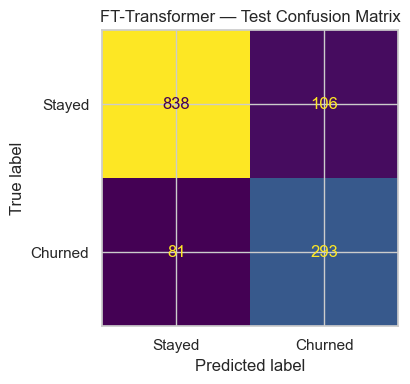

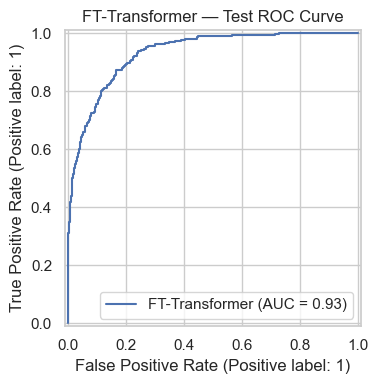

In [310]:
ft_Xte_num, ft_Xte_cat = ft_transform_raw(X_test, *ft_transform_kwargs)
ft_yte = np.asarray(y_test, dtype=np.float32).reshape(-1)
ft_test_loader = ft_loader(ft_Xte_num, ft_Xte_cat, y=None, shuffle=False)
ft_test_probs = ft_predict_proba(ft_model, ft_test_loader, ft_device)
ft_test_pred = (ft_test_probs >= ft_best_threshold).astype(int)
ft_test_metrics = ft_evaluate(ft_yte, ft_test_probs, ft_best_threshold, "Test")
display(pd.DataFrame([ft_test_metrics]).round(4))
print(classification_report(ft_yte.astype(int), ft_test_pred,
      target_names=["Stayed", "Churned"], zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(ft_yte.astype(int), ft_test_pred,
   display_labels=["Stayed", "Churned"], ax=ax, colorbar=False)
plt.title("FT-Transformer — Test Confusion Matrix")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(ft_yte.astype(int), ft_test_probs, ax=ax,
                                 name="FT-Transformer")
plt.title("FT-Transformer — Test ROC Curve")
plt.tight_layout()
plt.show()

##### Metadata + model save

In [311]:
ft_metadata = {"input_columns": list(X_train.columns),
               "standard_features": ft_std_cols, "minmax_features": ft_mm_cols,
               "categorical_features": ft_cat_cols, "vocab": ft_vocab,
               "cardinalities": ft_cardinalities, "model_config": FT_CONFIG,
               "n_numeric": len(ft_num_cols), "threshold": ft_best_threshold,
               "best_epoch": ft_best_epoch, "best_validation_auc": float(ft_best_auc),
               "training_variant": "Real training data only"}
joblib.dump(ft_metadata, "models/ft_transformer_metadata.pkl")
joblib.dump(preprocessor, "models/telecom_preprocessor.pkl")
pd.DataFrame([ft_val_default, ft_val_tuned, ft_test_metrics]).to_csv(
    "models/ft_transformer_metrics.csv", index=False)
ft_history_df.to_csv("models/ft_transformer_training_history.csv", index=False)
print("Saved:", ft_checkpoint)
print("Saved: models/ft_transformer_metadata.pkl")
print("Saved: models/telecom_preprocessor.pkl")


Saved: models\telecom_churn_ft_transformer.pt
Saved: models/ft_transformer_metadata.pkl
Saved: models/telecom_preprocessor.pkl


### Load saved model + same predictions test

In [312]:
ft_loaded_meta = joblib.load("models/ft_transformer_metadata.pkl")
ft_loaded_preprocessor = joblib.load("models/telecom_preprocessor.pkl")
ft_loaded_model = TelecomFTTransformer(
    n_numeric=ft_loaded_meta["n_numeric"],
    cardinalities=ft_loaded_meta["cardinalities"],
    **ft_loaded_meta["model_config"]
).to(ft_device)
ft_loaded_model.load_state_dict(torch.load(
    "models/telecom_churn_ft_transformer.pt", map_location=ft_device, weights_only=True))
ft_loaded_model.eval()

num, cat = ft_transform_raw(
    X_val.head(5), ft_loaded_preprocessor,
    ft_loaded_meta["standard_features"], ft_loaded_meta["minmax_features"],
    ft_loaded_meta["categorical_features"], ft_loaded_meta["vocab"])
ft_loaded_probs = ft_predict_proba(
    ft_loaded_model, ft_loader(num, cat, y=None), ft_device)
np.testing.assert_allclose(ft_loaded_probs, ft_val_probs[:5], rtol=1e-5, atol=1e-6)
print("Loaded model predictions match original model")
print(pd.DataFrame({"Probability of Churn": ft_loaded_probs,
                    "Predicted Churn": (ft_loaded_probs >= ft_loaded_meta["threshold"]).astype(int)}))


Loaded model predictions match original model
   Probability of Churn  Predicted Churn
0              0.853664                1
1              0.044485                0
2              0.418618                0
3              0.281435                0
4              0.901074                1


### DNN Accuracy

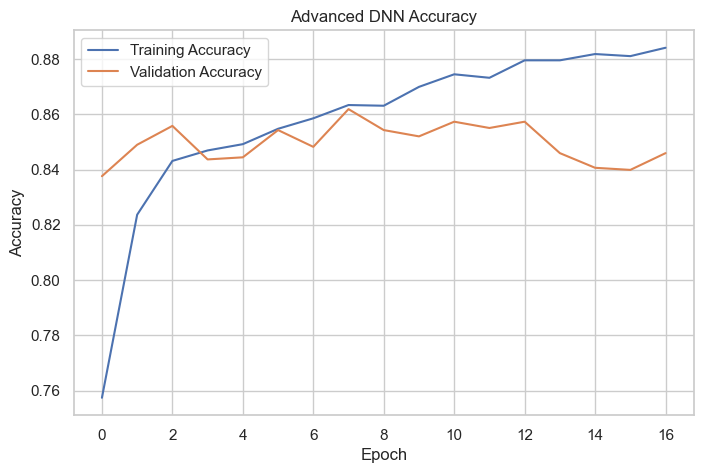

In [313]:
plt.figure(figsize=(8, 5))

plt.plot(
	dnn_history.history["accuracy"],
	label="Training Accuracy"
)

plt.plot(
	dnn_history.history["val_accuracy"],
	label="Validation Accuracy"
)

plt.title(
    "Advanced DNN Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()

plt.show()

In [314]:
### DNN loss graph

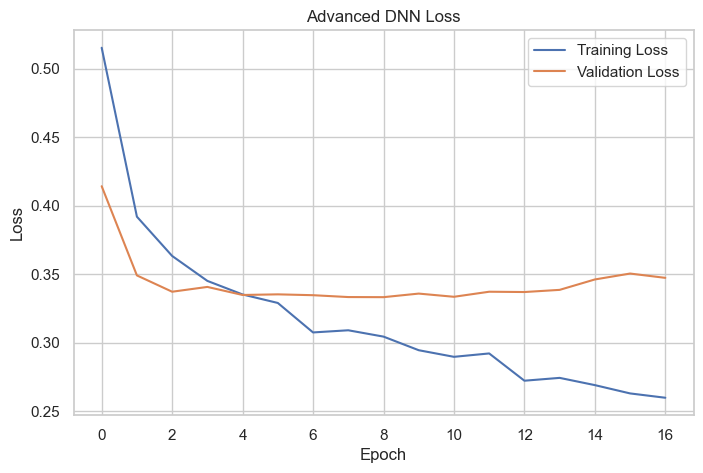

In [315]:
plt.figure(figsize=(8, 5))

plt.plot(
	dnn_history.history["loss"],
	label="Training Loss"
)

plt.plot(
	dnn_history.history["val_loss"],
	label="Validation Loss"
)

plt.title(
    "Advanced DNN Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()

plt.show()

## Stage 06: Final Model Evaluation & Comparison.


### * Import libraries

In [316]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
os.makedirs("evaluation_results", exist_ok=True)

### Prepare Validation and Test Data

In [317]:
# Use the already fitted preprocessor

def prepare_features(X):
    data = preprocessor.transform(X)

    if hasattr(data, "toarray"):
        data = data.toarray()

    return np.asarray(data, dtype=np.float32)


X_val_final = prepare_features(X_val)
X_test_final = prepare_features(X_test)

y_val_final = np.asarray(y_val).ravel()
y_test_final = np.asarray(y_test).ravel()

print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

Validation: (1318, 62)
Test: (1318, 62)


### Get Predictions from All Models

In [318]:
models = {
    "Logistic Regression": lr_model,
    "XGBoost": xgb_model,
    "CatBoost": cat_model,
    "DNN": dnn_model,
    "TabNet": tabnet_model,
    "FT-Transformer": ft_model
}

if "catboost_gan" in globals():
    models["CatBoost + CTGAN"] = catboost_gan

In [319]:
def get_probability(name, X):

    model = models[name]

    if name in ["CatBoost", "CatBoost + CTGAN"]:

        X_input = prepare_native_catboost(X)
        probability = model.predict_proba(X_input)[:, 1]

    elif name == "DNN":

        X_input = prepare_features(X)
        probability = model.predict(
            X_input, verbose=0
        ).ravel()

    elif name == "FT-Transformer":

        X_num, X_cat = ft_transform_raw(
            X, *ft_transform_kwargs
        )

        loader = ft_loader(
            X_num, X_cat,
            y=None, shuffle=False
        )

        probability = ft_predict_proba(
            model, loader, ft_device
        )

    else:

        X_input = prepare_features(X)
        probability = model.predict_proba(X_input)[:, 1]

    return np.asarray(probability).ravel()

### Find Best Threshold Using Validation Data

In [320]:
best_thresholds = {}

for name in models:

    probabilities = get_probability(name, X_val)

    best_f1 = -1
    best_threshold = 0.5

    for threshold in np.arange(0.20, 0.81, 0.05):

        predictions = (
            probabilities >= threshold
        ).astype(int)

        score = f1_score(
            y_val_final,
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = float(threshold)

    best_thresholds[name] = best_threshold

    print(
        name,
        "| Threshold:", round(best_threshold, 2),
        "| Validation F1:", round(best_f1, 4)
    )

Logistic Regression | Threshold: 0.35 | Validation F1: 0.7395
XGBoost | Threshold: 0.35 | Validation F1: 0.7841
CatBoost | Threshold: 0.35 | Validation F1: 0.7879
DNN | Threshold: 0.45 | Validation F1: 0.7413
TabNet | Threshold: 0.3 | Validation F1: 0.7277
FT-Transformer | Threshold: 0.55 | Validation F1: 0.7694
CatBoost + CTGAN | Threshold: 0.35 | Validation F1: 0.7719


### Final Test Evaluation

In [321]:
results = []
test_probabilities = {}

for name in models:

    probabilities = get_probability(name, X_test)

    test_probabilities[name] = probabilities

    predictions = (
        probabilities >= best_thresholds[name]
    ).astype(int)

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test_final, predictions
        ),

        "Precision": precision_score(
            y_test_final, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test_final, predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test_final, predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test_final, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8399,0.6909,0.7888,0.7366,0.9158
1,XGBoost,0.8467,0.7172,0.7594,0.7377,0.9246
2,CatBoost,0.8536,0.7303,0.7674,0.7484,0.9313
3,DNN,0.8505,0.7347,0.7406,0.7377,0.9104
4,TabNet,0.8149,0.6349,0.8182,0.7150,0.8915
5,FT-Transformer,0.8604,0.7351,0.7941,0.7635,0.9322
6,CatBoost + CTGAN,0.8543,0.7345,0.7620,0.7480,0.9266


### Compare All Models

In [322]:
comparison = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,FT-Transformer,0.8604,0.7351,0.7941,0.7635,0.9322
1,CatBoost,0.8536,0.7303,0.7674,0.7484,0.9313
2,CatBoost + CTGAN,0.8543,0.7345,0.7620,0.7480,0.9266
3,DNN,0.8505,0.7347,0.7406,0.7377,0.9104
4,XGBoost,0.8467,0.7172,0.7594,0.7377,0.9246
5,Logistic Regression,0.8399,0.6909,0.7888,0.7366,0.9158
6,TabNet,0.8149,0.6349,0.8182,0.7150,0.8915


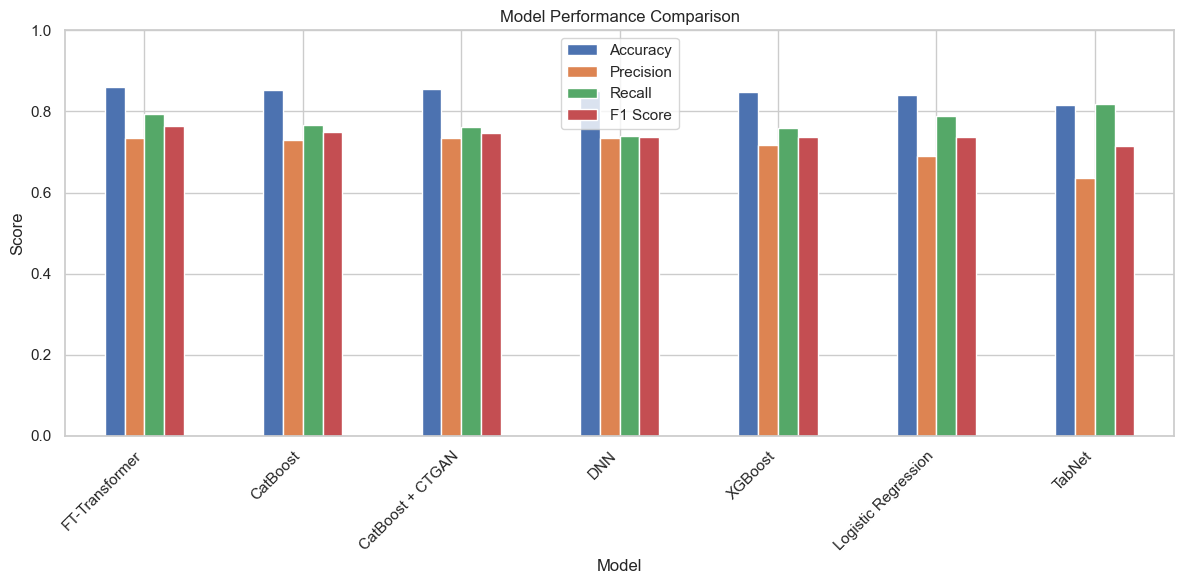

In [323]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### ROC Curve for All Models

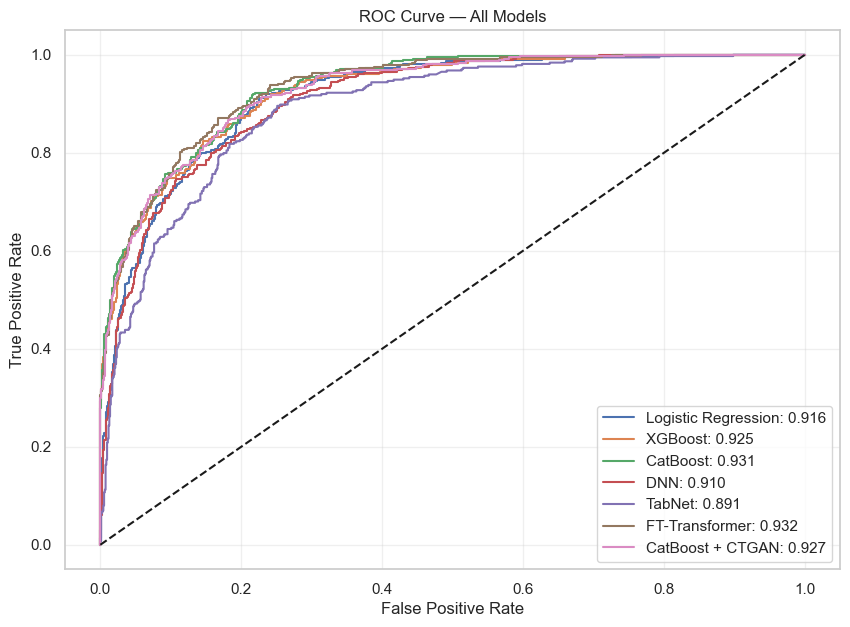

In [324]:
plt.figure(figsize=(10, 7))

for name, probability in test_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test_final, probability
    )

    auc = roc_auc_score(
        y_test_final, probability
    )

    plt.plot(
        fpr, tpr,
        label=f"{name}: {auc:.3f}"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.title("ROC Curve — All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Save Final Results

In [325]:
import os

os.makedirs("evaluation_results", exist_ok=True)

comparison.to_csv(
    "evaluation_results/final_model_comparison.csv",
    index=False
)

print("Final evaluation results saved!")

Final evaluation results saved!


## Save Best Model for FastAPI Deployment

### Check Best Model

In [326]:
print("Best Model:", best_thresholds)

best_model_name = comparison.loc[0, "Model"]
best_threshold = best_thresholds[best_model_name]

print("Best Model:", best_model_name)
print("Best Threshold:", round(best_threshold, 3))

best_model = models[best_model_name]

Best Model: {'Logistic Regression': 0.35, 'XGBoost': 0.35, 'CatBoost': 0.35, 'DNN': 0.44999999999999996, 'TabNet': 0.3, 'FT-Transformer': 0.5499999999999999, 'CatBoost + CTGAN': 0.35}
Best Model: FT-Transformer
Best Threshold: 0.55


### Save Preprocessor and Threshold

In [327]:
import os
import joblib
import torch

os.makedirs("models", exist_ok=True)

if best_model_name == "Logistic Regression":
    model_path = "models/best_model.pkl"
    joblib.dump(best_model, model_path)

elif best_model_name == "XGBoost":
    model_path = "models/best_model.json"
    best_model.save_model(model_path)

elif best_model_name in ["CatBoost", "CatBoost + CTGAN"]:
    model_path = "models/best_model.cbm"
    best_model.save_model(model_path)

elif best_model_name == "DNN":
    model_path = "models/best_model.keras"
    best_model.save(model_path)

elif best_model_name == "TabNet":
    model_path = best_model.save_model("models/best_tabnet")

elif best_model_name == "FT-Transformer":
    model_path = "models/best_ft_transformer.pt"
    torch.save(best_model.state_dict(), model_path)

else:
    raise ValueError("Unsupported model")

print("Best model saved:", model_path)

Best model saved: models/best_ft_transformer.pt


### Test One Customer Prediction

In [328]:
sample_customer = X_test.iloc[[0]]

probability = float(
    get_probability(
        best_model_name,
        sample_customer
    )[0]
)

prediction = int(
    probability >= best_thresholds[best_model_name]
)

print(f"Churn Probability: {probability:.2%}")

print(
    "Prediction:",
    "Churn" if prediction == 1 else "No Churn"
)

Churn Probability: 21.69%
Prediction: No Churn


## Explainable AI (SHAP)

In [329]:
import shap
from catboost import Pool
from IPython.display import display

os.makedirs("evaluation_results/shap", exist_ok=True)

print("SHAP libraries imported!")

SHAP libraries imported!


### Prepare SHAP Dataset

In [330]:
X_shap = prepare_native_catboost(
    X_val.sample(
        n=min(100, len(X_val)),
        random_state=42
    )
)

shap_pool = Pool(
    X_shap,
    cat_features=categorical_features
)

print("SHAP dataset:", X_shap.shape)

display(X_shap.head())

SHAP dataset: (100, 32)


,Gender,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,AverageMonthlySpend,TenureGroup
533,Male,22,No,1,0,72,No Offer,Yes,31.93,No,...,No,Credit Card,19.90,1529.65,0.0,0,2298.96,3828.61,21.245139,49+ months
38,Female,48,Yes,3,3,12,No Offer,Yes,19.28,No,...,No,Bank Withdrawal,20.30,224.50,0.0,0,231.36,455.86,18.708333,7-12 months
39,Male,60,Yes,3,7,27,Offer C,Yes,25.26,Yes,...,Yes,Bank Withdrawal,75.75,1929.00,0.0,0,682.02,2611.02,71.444444,25-48 months
7012,Male,65,No,0,0,15,Offer D,Yes,29.11,No,...,Yes,Bank Withdrawal,74.40,1074.30,0.0,0,436.65,1510.95,71.620000,13-24 months
4527,Male,31,No,0,0,5,No Offer,Yes,24.16,No,...,No,Credit Card,19.95,107.05,0.0,0,120.80,227.85,21.410000,0-6 months


### Calculate SHAP Values

In [331]:
shap_output = cat_model.get_feature_importance(
    data=shap_pool,
    type="ShapValues"
)

shap_values = shap_output[:, :-1]
base_values = shap_output[:, -1]

print("SHAP values:", shap_values.shape)
print("Number of features:", X_shap.shape[1])

SHAP values: (100, 32)
Number of features: 32


### Top 20 Important Features

In [332]:
importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    "Importance": np.abs(shap_values).mean(axis=0)
})

top20 = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(20)

display(top20)

,Feature,Importance
21,Contract,1.118794
4,Number of Referrals,0.633369
3,Number of Dependents,0.582270
5,Tenure in Months,0.561428
24,Monthly Charge,0.274357
23,Payment Method,0.220565
30,AverageMonthlySpend,0.184917
11,Internet Type,0.174074
1,Age,0.142884
28,Total Long Distance Charges,0.126059


### Top 20 Feature Importance Graph

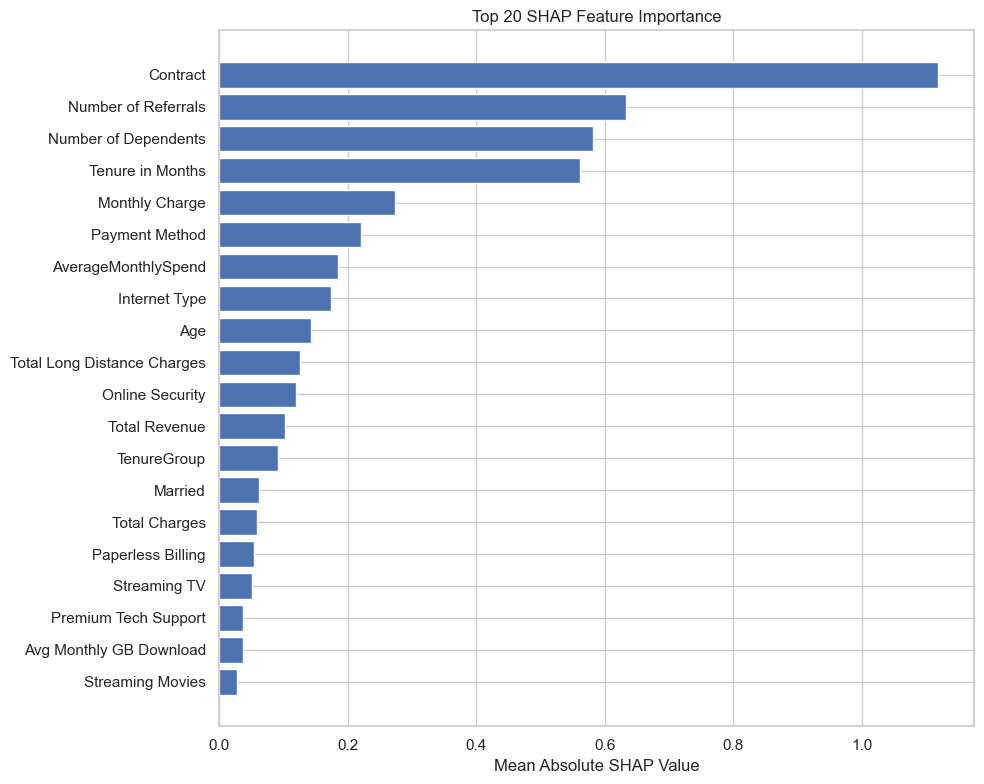

In [333]:
plt.figure(figsize=(10, 8))

plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1]
)

plt.title("Top 20 SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()

plt.savefig(
    "evaluation_results/shap/top20_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### SHAP Summary Plot

C:\Users\SIMON\AppData\Local\Temp\ipykernel_19320\3081107998.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


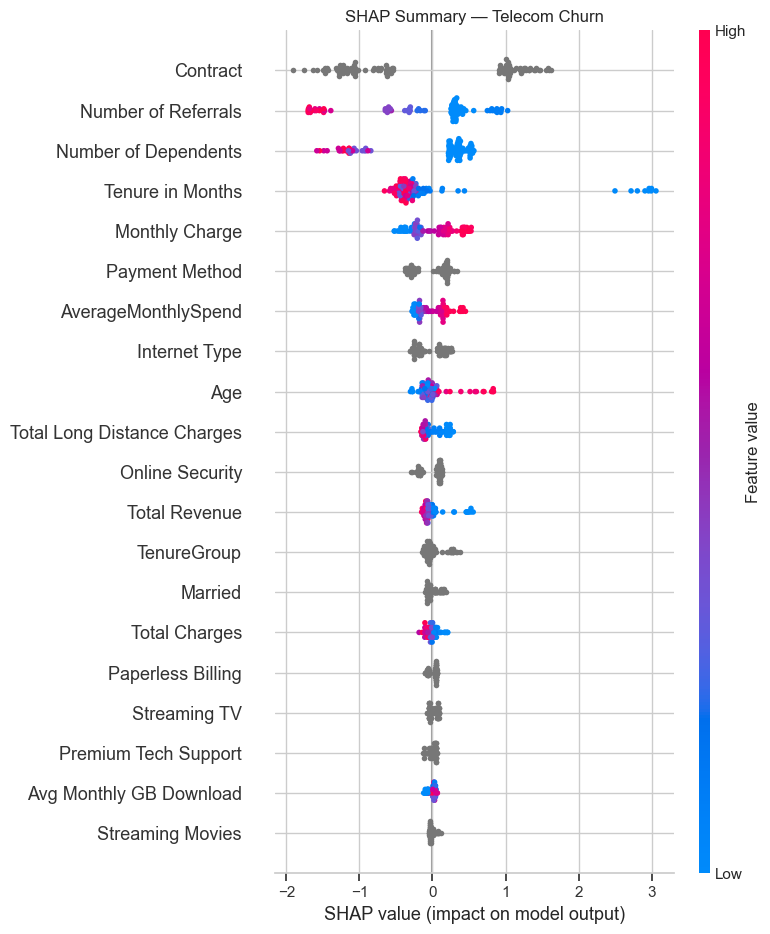

In [334]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_shap.columns.tolist(),
    max_display=20,
    show=False
)

plt.title("SHAP Summary — Telecom Churn")
plt.tight_layout()

plt.savefig(
    "evaluation_results/shap/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## SHAP Bar Plot

C:\Users\SIMON\AppData\Local\Temp\ipykernel_19320\108500715.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


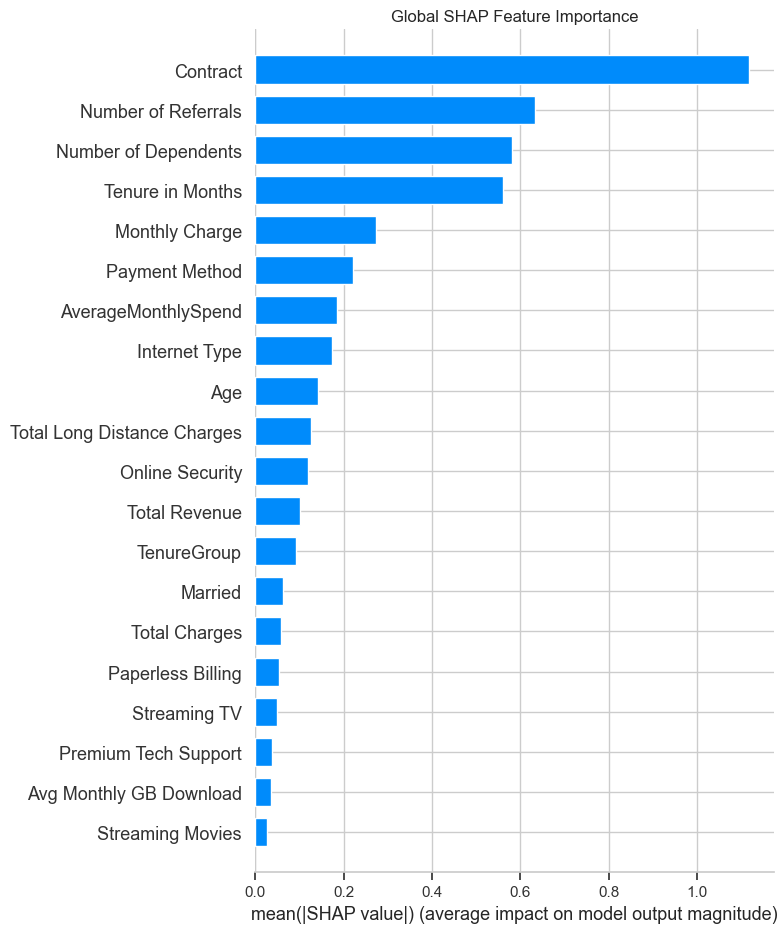

In [335]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    "evaluation_results/shap/shap_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Individual Customer Waterfall Plot

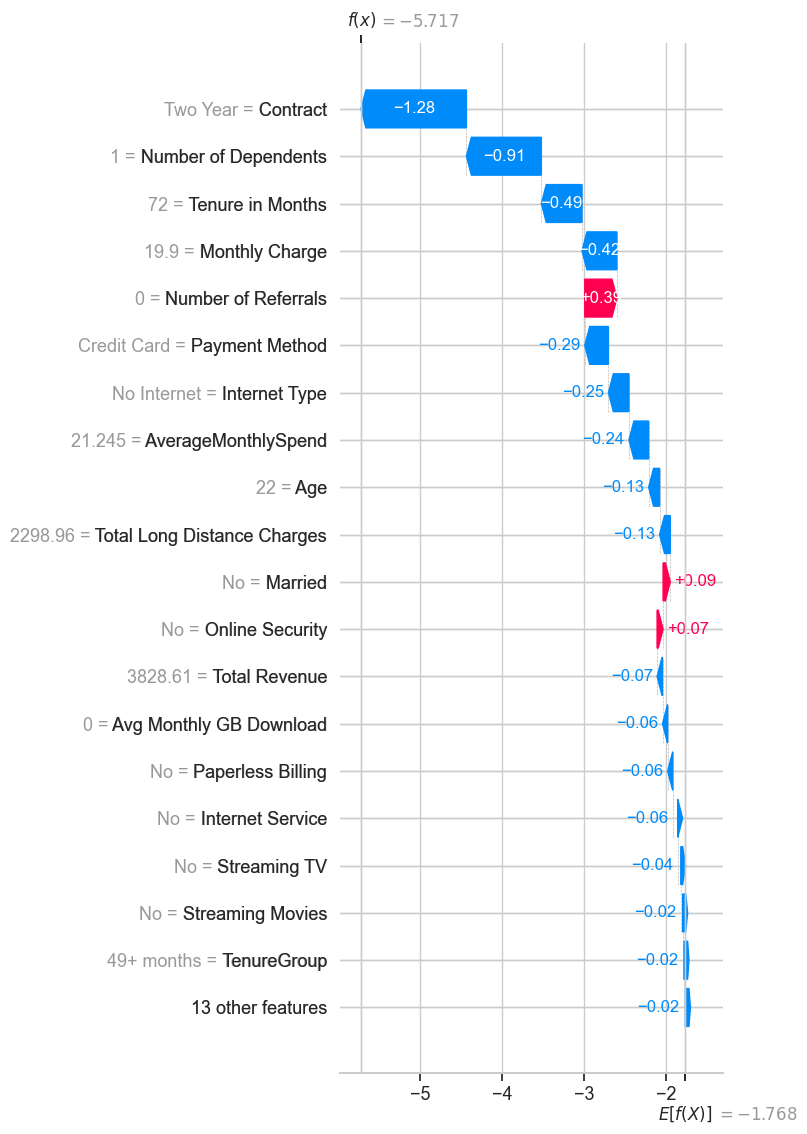

In [336]:
customer_index = 0

customer_shap = shap.Explanation(
    values=shap_values[customer_index],
    base_values=float(base_values[customer_index]),
    data=X_shap.iloc[customer_index].to_numpy(),
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    customer_shap,
    max_display=20,
    show=False
)

plt.tight_layout()

plt.savefig(
    "evaluation_results/shap/customer_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Predict That Customer

In [337]:
customer = X_shap.iloc[[0]]

probability = cat_model.predict_proba(
    customer
)[0, 1]

threshold = best_thresholds.get(
    "CatBoost", 0.5
)

prediction = int(probability >= threshold)

print(f"Churn Probability: {probability:.2%}")

print(
    "Prediction:",
    "Churn" if prediction == 1 else "No Churn"
)

Churn Probability: 0.33%
Prediction: No Churn


## Save SHAP Results

In [338]:
importance_df.to_csv(
    "evaluation_results/shap/feature_importance.csv",
    index=False
)

shap_results = pd.DataFrame(
    shap_values,
    columns=X_shap.columns,
    index=X_shap.index
)

shap_results.to_csv(
    "evaluation_results/shap/customer_shap_values.csv"
)

print("All SHAP results saved successfully!")

All SHAP results saved successfully!
